# Consumer Financial Complaints: Data Wrangling and EDA
**Springboard Data Science Career Track · Capstone Three** · Author: Jacob Paul

**Project:** Route consumer financial complaints to the right product/issue category and predict which ones end in **monetary relief**, using CFPB complaint narratives (NLP).

| Step | DSM stage | Goal |
|---|---|---|
| 1 | Data Collection | Locate and load the CFPB Consumer Complaint Database snapshot, verify the schema |
| 2 | Data Organization | Fix types, parse dates, group columns by role |
| 3 | Data Definition | Data dictionary, target definitions, leakage-risk columns |
| 4 | Data Cleaning | Missing values, duplicates, invalid values, outliers, label-taxonomy drift |
| 5 | Feature engineering for EDA | Calendar, text-shape and flag features |
| 6 | Exploratory Data Analysis | Univariate, bivariate, statistical tests, text, time, leakage audit |
| 7 | Outputs and summary | Cleaned data, small sample for GitHub, key findings |

Two prediction tasks drive every decision below:
1. **Routing:** predict `product` (and `issue`) from the complaint narrative.
2. **Relief:** predict whether the company closed the complaint with **monetary relief**.

**Run notes.** The 21 archive exports hold 17,533,918 complaints (about 10 GB of CSV). This notebook loads a uniform random 20% of rows (`SAMPLE_FRAC = 0.20` in section 1), about 3.5M complaints including about 770k narratives. That runs in roughly 10 minutes and stays under about 8 GB of RAM on a 16 GB MacBook Air. Because the sample is uniform, every share, rate and correlation is an unbiased estimate of the full-archive value. Row counts in the tables are for the sample (multiply by 5 for the archive). The raw data is not in the repo (see README).

In [1]:
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.feature_selection import chi2
from sklearn.metrics import mutual_info_score
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

pd.set_option("display.max_columns", 60)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

RANDOM_STATE = 42

# Paths: this notebook lives in notebooks/, data and reports are siblings of that folder.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = ROOT / "data"
PROCESSED_DIR = DATA_DIR / "processed"
SAMPLE_DIR = DATA_DIR / "sample"
FIG_DIR = ROOT / "reports" / "figures"
for d in (DATA_DIR, PROCESSED_DIR, SAMPLE_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)


def savefig(name):
    """Save the current figure to reports/figures and show it."""
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()


# Audit trail: row count after every wrangling step (shown again in section 7)
wrangling_log = []


def log_step(step, frame, note=""):
    wrangling_log.append({"step": step, "rows": len(frame), "columns": frame.shape[1], "note": note})


print("pandas", pd.__version__, "| numpy", np.__version__)
print("Project root:", ROOT.name, "(all paths below are relative to it)")

pandas 3.0.3 | numpy 2.4.6
Project root: consumer-complaints-capstone (all paths below are relative to it)


## 1. Data Collection

**Source:** the CFPB [Consumer Complaint Database Narratives Archive](https://www.consumerfinance.gov/foia-requests/foia-electronic-reading-room/cfpb-consumer-complaint-database-narratives-archive/), published in the CFPB FOIA reading room after the Bureau stopped publishing complaint narratives on August 14, 2026. It consists of 21 "full record" CSV exports (`CCDB_Export_1_December_2011_through_April_2018` to `CCDB_Export_21_August_2026`) with identical 16-column schemas, covering complaints received from December 1, 2011 to August 31, 2026, with no gaps or overlaps between files. Unzip all 21 into `data/raw/`. Every file is loaded and combined, and any complaint that appears twice is removed in section 4.2. Raw data is not tracked by git.

**Why this dataset fits the problem.** Every record carries the structured routing labels (`product`, `issue`), the company's closing response (the source of the relief label) and, for consumers who opted in, the free-text narrative the NLP models will use.

**Known limitations to keep in mind**
- Narratives exist only for consumers who consented to publication, so text-based work uses a self-selected subset (22% of all complaints). Narrative publication began in March 2015, so there is no text for 2011–2014.
- Narratives nearly disappear in 2026: the opt-in share falls from 22% in 2025 to about 2.5%, and the August 2026 export has a single narrative. The text corpus is effectively 2015–2025.
- The CFPB's product/issue taxonomy changed over time (checked in section 4.5).
- `consumer_consent_provided` and `consumer_disputed` are not in the archive exports. They are kept in the schema as empty columns so that the code also works on other CFPB extracts.

In [2]:
RAW_FILE = None      # optional override: one file, or a folder of files. Default: every CSV in data/raw
# Memory: the 21 exports hold 17.5M rows and 3.85M narratives (about 10 GB of CSV), which does not fit in a
# 16 GB laptop's RAM once text features are added. A uniform random row sample keeps every share, rate and
# correlation unbiased (no re-weighting needed) while cutting memory to about a fifth.
# 0.20 keeps about 3.5M complaints, about 770k narratives and about 20k monetary-relief cases. Use None for all rows (needs 48 GB+ of RAM).
SAMPLE_FRAC = 0.20
EXPECTED_ROWS = 17_533_918   # rows in the 21 archive exports (counted below on every run)

# Working schema. Mirrors publish the same CFPB data with slightly different headers, so names are normalised on load.
ALIASES = {
    "complaint_id": ["complaint_id"],
    "date_received": ["date_received"],
    "product": ["product"],
    "sub_product": ["sub_product"],
    "issue": ["issue"],
    "sub_issue": ["sub_issue"],
    "narrative": ["consumer_complaint_narrative", "complaint_what_happened", "narrative"],
    "company_public_response": ["company_public_response"],
    "company": ["company"],
    "state": ["state"],
    "zip_code": ["zip_code"],
    "tags": ["tags"],
    "consumer_consent_provided": ["consumer_consent_provided"],
    "submitted_via": ["submitted_via"],
    "date_sent_to_company": ["date_sent_to_company"],
    "company_response": ["company_response_to_consumer", "company_response"],
    "timely_response": ["timely_response"],
    "consumer_disputed": ["consumer_disputed"],
}
REQUIRED = ["complaint_id", "date_received", "product", "issue", "narrative", "company", "company_response"]


def snake(name):
    return re.sub(r"[^0-9a-z]+", "_", str(name).strip().lower()).strip("_")


def standardize_columns(frame):
    frame.columns = [snake(c) for c in frame.columns]
    rename = {}
    for canon, options in ALIASES.items():
        hit = next((o for o in options if o in frame.columns), None)
        if hit and hit != canon:
            rename[hit] = canon
    return frame.rename(columns=rename)


def find_raw_files(root):
    exts = (".parquet", ".csv", ".csv.gz", ".jsonl", ".json")
    files = sorted(p for p in root.rglob("*")
                   if p.is_file() and p.name.lower().endswith(exts)
                   and PROCESSED_DIR not in p.parents and SAMPLE_DIR not in p.parents)
    if not files:
        raise FileNotFoundError(
            f"No raw data file found under {root}. Put the CFPB exports in data/raw first (see README). "
            "Accepted: .parquet, .csv, .csv.gz, .json, .jsonl. Unzip any .zip files first.")
    return files


def export_number(path):
    """CFPB archive files are named CCDB_Export_<n>_<period>.csv; sort them in time order (1 = oldest)."""
    m = re.search(r"Export_(\d+)_", path.name)
    return (int(m.group(1)) if m else 10**6, path.name)


def load_raw(path, sample_frac=None, seed=RANDOM_STATE):
    """Load one file. Returns (frame, rows in the file). CSVs are sampled while reading, so skipped rows never use memory."""
    name = path.name.lower()
    if name.endswith(".parquet"):
        out = pd.read_parquet(path)
        n = len(out)
        return (out.sample(frac=sample_frac, random_state=seed) if sample_frac else out), n
    if name.endswith((".csv", ".csv.gz")):
        rng = np.random.default_rng(seed)
        seen = [0]

        def skip(i):                     # called once per record; also counts the file's rows
            if i == 0:
                return False             # header
            seen[0] = max(seen[0], i)
            return rng.random() > sample_frac

        # dtype=str keeps ZIP codes and IDs exactly as published; types are fixed in section 2
        out = pd.read_csv(path, dtype=str, skiprows=skip if sample_frac else None)
        return out, (seen[0] if sample_frac else len(out))
    try:
        out = pd.read_json(path, lines=name.endswith(".jsonl"), dtype=False)
    except ValueError:                      # a .json file that is really one record per line
        out = pd.read_json(path, lines=True, dtype=False)
    n = len(out)
    return (out.sample(frac=sample_frac, random_state=seed) if sample_frac else out), n


target = Path(RAW_FILE) if RAW_FILE else DATA_DIR / "raw"
raw_files = [target] if target.is_file() else sorted(find_raw_files(target), key=export_number)
print(f"Loading {len(raw_files)} file(s):")
parts, file_rows = [], []
for k, f in enumerate(raw_files):
    part, n_file = load_raw(f, SAMPLE_FRAC, seed=RANDOM_STATE + k)   # a different seed per file
    part = standardize_columns(part)
    file_rows.append({"file": f.name, "rows_in_file": n_file, "rows_loaded": len(part),
                      "first_date": part["date_received"].min(), "last_date": part["date_received"].max(),
                      "narratives_loaded": int(part["narrative"].notna().sum()) if "narrative" in part else 0})
    parts.append(part)
df = pd.concat(parts, ignore_index=True) if len(parts) > 1 else parts[0]
del parts

file_summary = pd.DataFrame(file_rows).set_index("file")
display(file_summary)
N_RAW_TOTAL = int(file_summary["rows_in_file"].sum())
print(f"Rows in the raw files: {N_RAW_TOTAL:,}  (expected {EXPECTED_ROWS:,} -> difference {N_RAW_TOTAL - EXPECTED_ROWS:+,})")
print(f"Rows loaded: {len(df):,}  |  columns: {df.shape[1]}"
      + (f"  |  random {SAMPLE_FRAC:.0%} sample of rows" if SAMPLE_FRAC else "  |  all rows"))
print(f"In-memory size: {df.memory_usage(deep=True).sum() / 1e9:.2f} GB")
log_step("1. raw exports loaded" + (f" ({SAMPLE_FRAC:.0%} sample)" if SAMPLE_FRAC else ""), df,
         f"{N_RAW_TOTAL:,} rows in the files")

Loading 21 file(s):


,rows_in_file,rows_loaded,first_date,last_date,narratives_loaded
file,,,,,
CCDB_Export_1_December_2011_through_April_2018.csv,1031863,206353,2011-12-01,2018-04-30,58294
CCDB_Export_2_May_2018_through_April_2021.csv,1041632,208751,2018-05-01,2021-04-30,88202
CCDB_Export_3_May_2021_through_October_2022.csv,977426,195277,2021-05-01,2022-10-31,81215
CCDB_Export_4_November_2022_through_August_2023.csv,987495,197813,2022-11-01,2023-08-31,78101
CCDB_Export_5_September_2023_through_March_2024.csv,945532,188464,2023-09-01,2024-03-31,63400
CCDB_Export_6_April_2024_through_July_2024.csv,839903,167688,2024-04-01,2024-07-31,55404
CCDB_Export_7_August_2024_through_October_2024.csv,824514,164512,2024-08-01,2024-10-31,45906
CCDB_Export_8_November_2024_through_December_2024.csv,591058,118841,2024-11-01,2024-12-31,31049
CCDB_Export_9_January_2025_through_February_2025.csv,811019,162054,2025-01-01,2025-02-28,52941


Rows in the raw files: 17,533,918  (expected 17,533,918 -> difference +0)
Rows loaded: 3,505,876  |  columns: 16  |  random 20% sample of rows
In-memory size: 2.24 GB


In [3]:
# Schema check: every required column must be present; optional ones that are absent are added as empty
missing_required = [c for c in REQUIRED if c not in df.columns]
if missing_required:
    raise KeyError(f"Required columns not found: {missing_required}. Columns present: {list(df.columns)}")

optional_missing = [c for c in ALIASES if c not in df.columns]
extra_cols = [c for c in df.columns if c not in ALIASES]
df = df[[c for c in ALIASES if c in df.columns]]


def present(cols):
    """Keep only the columns this snapshot actually has (the archive lacks some fields of other CFPB extracts)."""
    return [c for c in cols if c in df.columns]


print("Columns mapped to the working schema:", len(ALIASES) - len(optional_missing), "of", len(ALIASES))
if optional_missing:
    print("Optional columns absent from this snapshot (not created, so no constant columns enter the EDA):", optional_missing)
if extra_cols:
    print("Extra columns in the file that are not used here (dropped):", extra_cols)
display(df.head(3))

Columns mapped to the working schema: 16 of 18
Optional columns absent from this snapshot (not created, so no constant columns enter the EDA): ['consumer_consent_provided', 'consumer_disputed']


,complaint_id,date_received,product,sub_product,issue,sub_issue,narrative,company_public_response,company,state,zip_code,tags,submitted_via,date_sent_to_company,company_response,timely_response
0,1511123,2015-08-10,Mortgage,Conventional fixed mortgage,"Loan servicing, payments, escrow account",NaN,NaN,NaN,"CENTENNIAL LENDING, LLC",WY,82007,NaN,Web,2015-08-10,Closed,Yes
1,1742206,2016-01-13,Debt collection,Non-federal student loan,Communication tactics,Frequent or repeated calls,NaN,NaN,HIGHER EDUCATION STUDENT ASSISTANCE AUTHORITY (HESAA),NJ,07095,NaN,Postal mail,2016-01-13,Closed with explanation,Yes
2,1767805,2016-02-01,Student loan,Non-federal student loan,Dealing with my lender or servicer,Received bad information about my loan,I am very very very concerned with HESSA and the XXXX arrangement with private school loan lending. I have been unfo...,Company believes it acted appropriately as authorized by contract or law,HIGHER EDUCATION STUDENT ASSISTANCE AUTHORITY (HESAA),NJ,080XX,NaN,Web,2016-02-04,Closed with explanation,Yes


## 2. Data Organization

Goals: get every column into a sensible type, make blanks real missing values, and group columns by the role they will play. Text is stripped of surrounding whitespace, empty strings become missing, IDs become integers and the two date columns become datetimes (unparseable dates become `NaT` and are counted).

In [4]:
def parse_dates(s):
    """ISO first, then US month/day/year as a fallback. Unparseable values become NaT."""
    if pd.api.types.is_datetime64_any_dtype(s):
        return s
    s = s.astype("string")
    out = pd.to_datetime(s, errors="coerce", format="ISO8601")
    bad = out.isna() & s.notna()
    if bad.any():
        out.loc[bad] = pd.to_datetime(s[bad], errors="coerce", format="%m/%d/%Y")
    return out


DATE_COLS = ["date_received", "date_sent_to_company"]
TEXT_COLS = [c for c in df.columns if c not in DATE_COLS + ["complaint_id"]]

for c in TEXT_COLS:
    df[c] = df[c].astype("string").str.strip().replace("", pd.NA)

df["complaint_id"] = pd.to_numeric(df["complaint_id"], errors="coerce").astype("Int64")

for c in DATE_COLS:
    before_na = df[c].isna().sum()
    df[c] = parse_dates(df[c])
    print(f"{c}: {df[c].isna().sum() - before_na:,} values could not be parsed (newly missing)")

COLUMN_GROUPS = {
    "Identifier": ["complaint_id"],
    "Dates": ["date_received", "date_sent_to_company"],
    "Routing labels (product taxonomy)": ["product", "sub_product", "issue", "sub_issue"],
    "Free text": ["narrative"],
    "Company": ["company", "company_public_response", "company_response", "timely_response", "consumer_disputed"],
    "Consumer / geography": ["state", "zip_code", "tags", "consumer_consent_provided"],
    "Submission channel": ["submitted_via"],
}
for group, cols in COLUMN_GROUPS.items():
    print(f"{group:36s} {present(cols)}")

structure = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "non_null": df.notna().sum(),
    "non_null_pct": df.notna().mean() * 100,
})
display(structure)
log_step("2. types fixed, blanks -> NaN", df)

date_received: 0 values could not be parsed (newly missing)
date_sent_to_company: 0 values could not be parsed (newly missing)
Identifier                           ['complaint_id']
Dates                                ['date_received', 'date_sent_to_company']
Routing labels (product taxonomy)    ['product', 'sub_product', 'issue', 'sub_issue']
Free text                            ['narrative']
Company                              ['company', 'company_public_response', 'company_response', 'timely_response']
Consumer / geography                 ['state', 'zip_code', 'tags']
Submission channel                   ['submitted_via']


,dtype,non_null,non_null_pct
complaint_id,Int64,3505876,100.000
date_received,datetime64[us],3505876,100.000
product,string,3505876,100.000
sub_product,string,3458921,98.661
issue,string,3505875,100.000
sub_issue,string,3319456,94.683
narrative,string,769880,21.960
company_public_response,string,1940178,55.341
company,string,3505876,100.000
state,string,3493252,99.640


## 3. Data Definition

### 3.1 Data dictionary
Each column is tagged with the role it plays in the two tasks. The most important distinction is **what is known when the complaint is filed** versus **what only exists after the company has responded** (post-outcome columns). Using post-outcome columns to predict relief would be target leakage, so they are only analysed here to prove they must be excluded.

In [5]:
DICTIONARY = [
    ("complaint_id", "Unique complaint identifier assigned by the CFPB", "Identifier"),
    ("date_received", "Date the CFPB received the complaint (time axis for the time-based split)", "Known at filing"),
    ("product", "Product the consumer is complaining about (top-level category)", "Routing label"),
    ("sub_product", "More specific product category; not always provided", "Routing label (level 2)"),
    ("issue", "Issue category chosen by the consumer", "Routing label"),
    ("sub_issue", "More specific issue; not always provided", "Routing label (level 2)"),
    ("narrative", "Consumer's free-text description. Opt-in only; personal data redacted as XXXX", "Text feature"),
    ("company_public_response", "Optional public statement the company chose to post about its response", "Post-outcome (exclude)"),
    ("company", "Company the complaint is about", "Known at filing"),
    ("state", "Consumer's state or territory", "Known at filing"),
    ("zip_code", "Consumer's ZIP code, partly masked by the CFPB", "Known at filing"),
    ("tags", "Older American / Servicemember flags", "Known at filing"),
    ("consumer_consent_provided", "Whether the consumer consented to publishing the narrative", "Known at filing (tied to narrative opt-in)"),
    ("submitted_via", "Channel used to submit (web, phone, referral, ...)", "Known at filing"),
    ("date_sent_to_company", "Date the CFPB forwarded the complaint to the company", "Post-submission (CFPB processing)"),
    ("company_response", "Company's closing response to the consumer", "Outcome (source of relief target)"),
    ("timely_response", "Whether the company responded on time", "Post-outcome (exclude)"),
    ("consumer_disputed", "Whether the consumer disputed the response (CFPB retired this field in 2017)", "Post-outcome (exclude)"),
]
data_dictionary = pd.DataFrame(DICTIONARY, columns=["column", "description", "role"]).set_index("column")
data_dictionary = data_dictionary.loc[present(data_dictionary.index)]
data_dictionary["dtype"] = df.dtypes.astype(str)
data_dictionary["non_null_pct"] = df.notna().mean() * 100
data_dictionary["n_unique"] = pd.array([pd.NA if c == "narrative" else df[c].nunique() for c in data_dictionary.index],
                                        dtype="Int64")   # narrative skipped: hashing millions of long strings is slow
display(data_dictionary)

POST_OUTCOME = ["company_public_response", "timely_response", "consumer_disputed",
                "company_response", "date_sent_to_company", "days_to_company"]

,description,role,dtype,non_null_pct,n_unique
column,,,,,
complaint_id,Unique complaint identifier assigned by the CFPB,Identifier,Int64,100.000,3505876
date_received,Date the CFPB received the complaint (time axis for the time-based split),Known at filing,datetime64[us],100.000,5386
product,Product the consumer is complaining about (top-level category),Routing label,string,100.000,21
sub_product,More specific product category; not always provided,Routing label (level 2),string,98.661,86
issue,Issue category chosen by the consumer,Routing label,string,100.000,178
sub_issue,More specific issue; not always provided,Routing label (level 2),string,94.683,268
narrative,Consumer's free-text description. Opt-in only; personal data redacted as XXXX,Text feature,string,21.960,<NA>
company_public_response,Optional public statement the company chose to post about its response,Post-outcome (exclude),string,55.341,11
company,Company the complaint is about,Known at filing,string,100.000,5799


### 3.2 Target definitions
- **Routing target:** `product` (harmonised in section 4.5) and `issue`.
- **Relief target:** `relief = 1` if `company_response == "Closed with monetary relief"`, `0` for any other *final* closing response, and missing (excluded from relief modelling) when there is no final outcome or the response cannot be classified as monetary or not.

First, look at what the response column actually contains before committing to a mapping.

In [6]:
resp_counts = df["company_response"].value_counts(dropna=False).rename("n").to_frame()
resp_counts["share"] = resp_counts["n"] / resp_counts["n"].sum()
display(resp_counts)

RELIEF_MAP = {
    "Closed with monetary relief": 1.0,
    "Closed with non-monetary relief": 0.0,
    "Closed with explanation": 0.0,
    "Closed without relief": 0.0,
    "Closed": 0.0,
    # No final outcome, or relief type unknown -> excluded from the relief target
    "Closed with relief": np.nan,   # newer CFPB label that does not say whether the relief was monetary
    "In progress": np.nan,
    "Untimely response": np.nan,
}
unmapped = sorted(set(df["company_response"].dropna().unique()) - set(RELIEF_MAP))
print("Response labels not covered by RELIEF_MAP (will be excluded from the relief target):", unmapped or "none")

# Evidence for the mapping: when each label was in use, overall and among complaints that have a narrative
resp_year = pd.crosstab(df["company_response"].fillna("<missing>"), df["date_received"].dt.year)
display(resp_year)
display(pd.crosstab(df["company_response"].fillna("<missing>"), df["narrative"].notna().rename("has_narrative"),
                    normalize="columns").mul(100).round(2))

,n,share
company_response,,
Closed with explanation,2163647,0.617
Closed with non-monetary relief,1188142,0.339
In progress,95901,0.027
Closed with monetary relief,43539,0.012
Untimely response,6683,0.002
Closed,3524,0.001
Closed without relief,3461,0.001
Closed with relief,975,0.000
<NA>,4,0.000


Response labels not covered by RELIEF_MAP (will be excluded from the relief target): none


date_received,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
company_response,,,,,,,,,,,,,,,,
<missing>,0,0,0,0,0,0,0,0,0,0,0,0,1,3,0,0
Closed,0,337,612,690,841,747,297,0,0,0,0,0,0,0,0,0
Closed with explanation,4,7249,16369,23497,26068,30599,40601,42210,44602,80574,87401,104332,144623,268234,638448,608836
Closed with monetary relief,0,1339,1790,1886,2148,2319,2314,2302,2295,2555,2789,3450,4056,4799,5153,4344
Closed with non-monetary relief,1,1426,2873,4354,4464,4699,5075,6828,8536,5504,8827,52373,109110,273292,441552,259228
Closed with relief,118,857,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Closed without relief,333,3128,0,0,0,0,0,0,0,0,0,0,0,0,0,0
In progress,0,0,0,0,0,0,0,0,0,0,0,0,0,0,59,95842
Untimely response,2,52,10,64,104,139,212,253,193,178,185,118,159,299,1910,2805


has_narrative,False,True
company_response,,
<missing>,0.000,0.000
Closed,0.100,0.100
Closed with explanation,60.370,66.500
Closed with monetary relief,0.870,2.570
Closed with non-monetary relief,34.840,30.530
Closed with relief,0.040,0.000
Closed without relief,0.130,0.000
In progress,3.500,0.000
Untimely response,0.160,0.300


**Relief mapping: decisions checked against the data (tables above)**
- The archive uses 8 response labels. `RELIEF_MAP` covers all of them, so nothing is silently dropped.
- `Closed with relief` / `Closed without relief` were used only in 2011–2012, before narratives existed (March 2015). "With relief" does not say whether the relief was monetary, so it is excluded (NaN). "Without relief" is a clear 0.
- `Closed` (2012–2017, 0.1% of rows) was in use at the same time as `Closed with monetary relief`. A company paying money back would have used the explicit label, so `Closed` maps to 0.
- `In progress` (2.7% of all rows, 96k in the sample) is almost entirely 2026 complaints still open when the archive was frozen. **Almost no complaint with a narrative is in progress** (114 of 3.85M in the full archive), so the relief analysis loses almost nothing here. `Untimely response` has no outcome and is excluded.
- Monetary relief is 2.6% of narrative complaints vs 0.9% of complaints without one. The narrative subset is not a random sample of outcomes, which is noted for the modelling step.

## 4. Data Cleaning

### 4.1 Missing values
Missingness is examined three ways: how much, whether it is related to time, and *why* it is missing. The reason decides the treatment, so no blanket imputation is applied.

,missing_n,missing_pct
tags,3344896,95.408
narrative,2735996,78.040
company_public_response,1565698,44.659
sub_issue,186420,5.317
sub_product,46955,1.339
state,12624,0.360
zip_code,490,0.014
company_response,4,0.000
issue,1,0.000
complaint_id,0,0.000


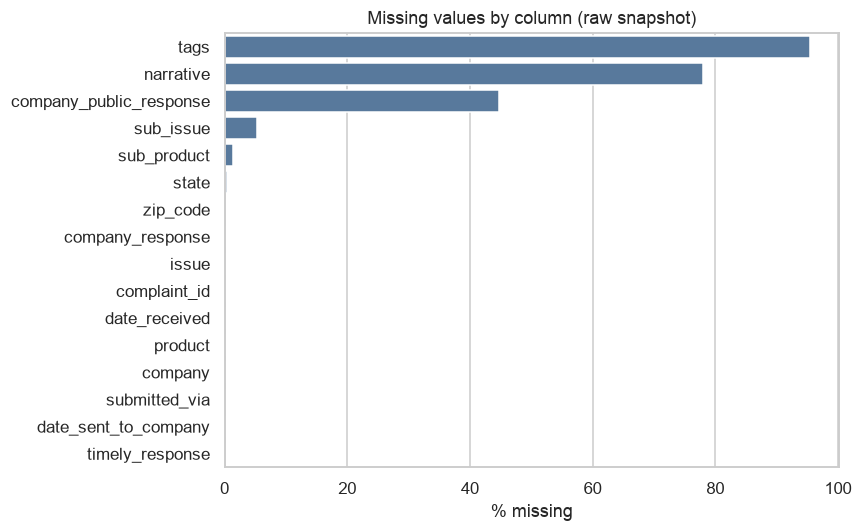

In [7]:
missing = pd.DataFrame({"missing_n": df.isna().sum(), "missing_pct": df.isna().mean() * 100})
missing = missing.sort_values("missing_pct", ascending=False)
display(missing)

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(x="missing_pct", y=missing.index, data=missing, color="#4C78A8", ax=ax)
ax.set_xlabel("% missing")
ax.set_ylabel("")
ax.set_title("Missing values by column (raw snapshot)")
savefig("01_missing_by_column")

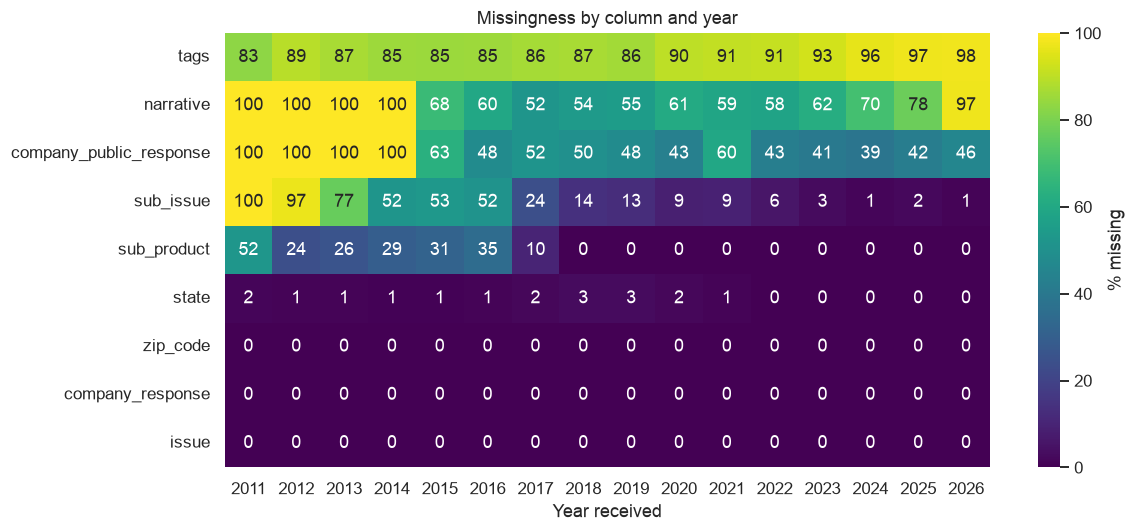

In [8]:
# Is missingness tied to time? (structural gaps show up as a column that switches on or off in certain years)
year = df["date_received"].dt.year
plausible = year.between(2011, pd.Timestamp.today().year)     # impossible dates are handled formally in 4.3
cols_with_gaps = missing.index[missing["missing_pct"] > 0].tolist()
miss_by_year = (pd.DataFrame({c: df.loc[plausible, c].isna() for c in cols_with_gaps})
                .groupby(year[plausible].astype(int)).mean() * 100)

fig, ax = plt.subplots(figsize=(11, 5))
sns.heatmap(miss_by_year.T, cmap="viridis", vmin=0, vmax=100, annot=len(miss_by_year) <= 16, fmt=".0f",
            cbar_kws={"label": "% missing"}, ax=ax)
ax.set_xlabel("Year received")
ax.set_title("Missingness by column and year")
savefig("02_missing_by_year")

**Decisions (driven by the tables above)**

| Column(s) | Reason it is missing | Treatment |
|---|---|---|
| `narrative` | Structural: only consumers who opted in have one. Missing is *not* random. | Never imputed. Keep the row, create `has_narrative`, and run text work on the narrative subset. |
| `consumer_disputed`, `consumer_consent_provided` | Not published in the archive exports at all (100% absent). | Not created: a constant column carries no information. |
| `company_public_response`, `sub_product`, `sub_issue` | Optional fields that companies/consumers leave blank (45%, 1%, 5%). `sub_product` is blank mainly for the 2012–2016 "Credit reporting" and "Credit card" labels, which had no sub-products (see heatmap). | Explicit `Missing` category, because "not provided" is itself informative. |
| `tags` | Blank means no tag applies (95% blank). | Fill with `None`. |
| `state`, `zip_code` | Not provided or masked (0.4% / under 0.1% missing). | `Missing` category; ZIP is reduced to its first three digits. |
| `complaint_id`, `date_received`, `product` | Rows without them cannot be placed on the time axis or labelled. | Drop the row (counted below). |
| `company_response` | Needed for the relief label only (4 blanks in the sample). | Keep the row for routing; relief stays missing. |

Imputation (mean, mode, model-based) is deliberately avoided: the missing values are either structural or informative, and filling them would invent data.

In [9]:
# 4.1 applied: drop rows that cannot be placed or labelled
req = ["complaint_id", "date_received", "product"]
drop_mask = df[req].isna().any(axis=1)
print("Rows missing complaint_id / date_received / product:", f"{int(drop_mask.sum()):,}")
df = df.loc[~drop_mask].copy()
log_step("4.1 dropped rows missing id/date/product", df, f"{int(drop_mask.sum()):,} rows")

# Standardise geography
VALID_STATES = set("""AL AK AZ AR CA CO CT DE FL GA HI ID IL IN IA KS KY LA ME MD MA MI MN MS MO MT NE NV NH NJ NM NY NC ND OH
OK OR PA RI SC SD TN TX UT VT VA WA WV WI WY DC PR VI GU AS MP AA AE AP FM MH PW UM""".split())
df["state"] = df["state"].str.upper().replace({"UNITED STATES MINOR OUTLYING ISLANDS": "UM"})   # only full name seen in the data
bad_state = df["state"].notna() & ~df["state"].isin(VALID_STATES)
print("Invalid state codes set to missing:", f"{int(bad_state.sum()):,}",
      "| examples:", df.loc[bad_state, "state"].value_counts().head(5).to_dict())
df.loc[bad_state, "state"] = pd.NA

# ZIP codes are partly masked (e.g. 123XX). Keep only the 3-digit prefix, which is the usable part.
df["zip3"] = df["zip_code"].str.extract(r"^(\d{3})", expand=False)
print(f"ZIP present but not usable (fully masked or malformed): {int((df['zip_code'].notna() & df['zip3'].isna()).sum()):,}")

# Light company-name normalisation (case, whitespace, trailing punctuation). Parent-company mapping is out of scope.
n_company_before = df["company"].nunique()
df["company"] = (df["company"].str.upper().str.replace(r"\s+", " ", regex=True)
                 .str.replace(r"[\s,.]+$", "", regex=True))
print(f"Distinct company names: {n_company_before:,} -> {df['company'].nunique():,} after normalisation")

Rows missing complaint_id / date_received / product: 0
Invalid state codes set to missing: 0 | examples: {}


ZIP present but not usable (fully masked or malformed): 27,953


Distinct company names: 5,799 -> 5,792 after normalisation


### 4.2 Duplicates
Two kinds are checked:
1. **Duplicate `complaint_id`.** This is a hard key, so any repeat is a true duplicate and is dropped.
2. **Duplicate content from the same consumer.** Same narrative, company, product, issue, date received, **state and ZIP code** under different IDs. These are re-submissions and are dropped, because identical text on both sides of a train/test split would inflate model scores.

*Why location is part of the key (data-driven):* without it, the same check flagged about 8% of narratives. But in about 76% of those groups the identical text came from **different ZIP codes**, and 24% of groups even had different company responses. These are template letters (mostly credit-repair and dispute templates) filed by different people, not re-submissions. Deleting them would remove real complaints.

Identical narratives from different consumers, dates or companies are real separate complaints. They are kept and flagged with `narrative_hash` / `narrative_repeat_count` so they can be grouped at split time. (With `SAMPLE_FRAC`, repeat counts are within the sample, so the full-archive counts are about five times higher.)

In [10]:
# (a) duplicate IDs
dup_id = df.duplicated("complaint_id", keep="first")
print(f"Duplicate complaint_id rows: {int(dup_id.sum()):,}")
df = df.loc[~dup_id].copy()
log_step("4.2a dropped duplicate complaint_id", df, f"{int(dup_id.sum()):,} rows")

# (b) duplicate content (hash the key columns instead of comparing long strings)
DUP_KEY = ["narrative", "company", "product", "issue", "date_received"]
loose = pd.util.hash_pandas_object(df[DUP_KEY], index=False).duplicated(keep="first") & df["narrative"].notna()
key = pd.util.hash_pandas_object(df[DUP_KEY + ["state", "zip_code"]], index=False)
dup_content = key.duplicated(keep="first") & df["narrative"].notna()
print(f"Same text + company + product + issue + date, any consumer:     {int(loose.sum()):,}  (not dropped)")
print(f"... and same state + ZIP, i.e. the same consumer re-submitting: {int(dup_content.sum()):,}  (dropped)")
df = df.loc[~dup_content].copy()
log_step("4.2b dropped duplicate content", df, f"{int(dup_content.sum()):,} rows")

# (c) templated narratives repeated across different complaints: flag, do not drop
narr_hash = pd.util.hash_pandas_object(df["narrative"], index=False).astype("UInt64")
df["narrative_hash"] = narr_hash.mask(df["narrative"].isna())
df["narrative_repeat_count"] = (df.groupby("narrative_hash")["complaint_id"].transform("size")
                                .fillna(0).astype("int32"))
n_repeat_rows = int((df["narrative_repeat_count"] > 1).sum())
print(f"Rows whose narrative text also appears in another complaint: {n_repeat_rows:,} "
      f"({n_repeat_rows / max(int(df['narrative'].notna().sum()), 1):.2%} of narratives)")

top_rep = (df[df["narrative_repeat_count"] > 1].drop_duplicates("narrative_hash")
           .nlargest(5, "narrative_repeat_count")[["narrative_repeat_count", "narrative"]])
top_rep["narrative"] = top_rep["narrative"].str.slice(0, 140)
display(top_rep)

Duplicate complaint_id rows: 0


Same text + company + product + issue + date, any consumer:     61,142  (not dropped)
... and same state + ZIP, i.e. the same consumer re-submitting: 3,726  (dropped)


Rows whose narrative text also appears in another complaint: 209,868 (27.39% of narratives)


,narrative_repeat_count,narrative
637315,5340,In accordance with the Fair Credit Reporting act. The List of accounts below has violated my federally protected con...
459887,4747,My credit reports are inaccurate. These inaccuracies are causing creditors to deny me credit. You have the duty to r...
1711405,3605,"You have reported inaccurate and unauthorized accounts on my credit report, which is a violation of the Fair Credit ..."
965311,3004,"Upon reviewing my credit report, I have identified inaccurate accounts that need reporting and correction through yo..."
1207158,2430,"I am writing to have the following information removed from my credit file, the items that I need deleted are going ..."


### 4.3 Invalid values and date outliers
Checks: dates outside the plausible window, and a forwarding date earlier than the received date (impossible). The CFPB opened in July 2011, so nothing before 2011 is valid and nothing can be dated in the future.

In [11]:
MIN_DATE = pd.Timestamp("2011-01-01")
MAX_DATE = pd.Timestamp.today().normalize()
print("Observed date_received range:", df["date_received"].min().date(), "->", df["date_received"].max().date())

out_of_range = (df["date_received"] < MIN_DATE) | (df["date_received"] > MAX_DATE)
print(f"date_received outside [{MIN_DATE.date()}, {MAX_DATE.date()}]: {int(out_of_range.sum()):,} rows (dropped)")
df = df.loc[~out_of_range].copy()
log_step("4.3 dropped impossible date_received", df, f"{int(out_of_range.sum()):,} rows")

df["days_to_company"] = (df["date_sent_to_company"] - df["date_received"]).dt.days.astype("float32")
neg = df["days_to_company"] < 0
print(f"Forwarded before received (impossible): {int(neg.sum()):,} rows -> days_to_company set to missing")
df.loc[neg, "days_to_company"] = np.nan

display(df["days_to_company"].describe(percentiles=[.5, .9, .99, .999]).to_frame().T)

Observed date_received range: 2011-12-01 -> 2026-08-31
date_received outside [2011-01-01, 2026-11-21]: 0 rows (dropped)
Forwarded before received (impossible): 1,405 rows -> days_to_company set to missing


,count,mean,std,min,50%,90%,99%,99.9%,max
days_to_company,"3,500,745.000",0.611,5.568,0.000,0.000,0.000,16.000,59.000,"1,748.000"


### 4.4 Narrative length and redaction: outliers
Very short narratives ("I was charged.") or narratives that are almost entirely redaction tokens (`XXXX`) carry no usable text signal. Very long narratives can dominate TF-IDF and slow vectorisation. Rather than deleting rows, a `text_usable` flag marks narratives long enough to model, and a `long_outlier` flag marks the extreme tail (IQR fences on log word count). The minimum length is chosen from the distribution below.

In [12]:
has_text = df["narrative"].notna()
df["char_len"] = df["narrative"].str.len().astype("float32")
df["word_count"] = df["narrative"].str.count(r"\S+").astype("float32")
# Redaction tokens: any whitespace-separated word containing "XX" (XXXX, masked dates like XX/XX/XXXX, "{$XXXX}").
# Counting per word keeps xxxx_count <= word_count, so the redacted share is a true proportion.
df["xxxx_count"] = df["narrative"].str.count(r"\S*XX\S*").astype("float32")
df["real_word_count"] = (df["word_count"] - df["xxxx_count"]).clip(lower=0)   # words left after removing redactions

pcts = [.001, .01, .05, .25, .5, .75, .95, .99, .999]
display(df.loc[has_text, ["char_len", "word_count", "real_word_count", "xxxx_count"]].quantile(pcts))

thr = pd.DataFrame({"min_real_words": [3, 5, 10, 15, 20, 30]})
thr["share_of_narratives_below"] = [(df.loc[has_text, "real_word_count"] < t).mean() for t in thr["min_real_words"]]
display(thr)

print("\nA random sample of the shortest narratives (what would be lost at a 10-word cut-off):")
short = df.loc[has_text & (df["real_word_count"] < 10), "narrative"]
for t in short.sample(min(8, len(short)), random_state=RANDOM_STATE).tolist():
    print("  -", t[:140])

,char_len,word_count,real_word_count,xxxx_count
0.001,31.000,5.000,4.000,0.000
0.010,63.000,11.000,10.000,0.000
0.050,127.000,22.000,20.000,0.000
0.250,348.000,61.000,56.000,0.000
0.500,672.000,117.000,105.000,4.000
0.750,"1,224.000",215.000,197.000,14.000
0.950,"3,008.000",518.000,483.000,61.000
0.990,"5,875.000","1,021.000",960.000,153.000
0.999,"14,374.235","2,461.000","2,266.000",390.847


,min_real_words,share_of_narratives_below
0,3,0.001
1,5,0.002
2,10,0.010
3,15,0.024
4,20,0.047
5,30,0.091



A random sample of the shortest narratives (what would be lost at a 10-word cut-off):
  - I never applied for any Auto Loan
  - Noticed 2 Bankruptcies on my credit report
  - The personal information on my credit report were outdated.
  - calls twice a day leave message or says nothing
  - Suspected inaccurate overdraft fees.
  - Victim of Equifax Data Breach. 
Please see attached Report.
  - I am a victim of identity theft
  - I did not authorize these inquiries.


Narratives present:            766,154
Usable (>= 10 real words):      758,548
Too short / mostly redacted:   7,606
Long-tail outliers (flagged):  3,486  (> 1,354 words)


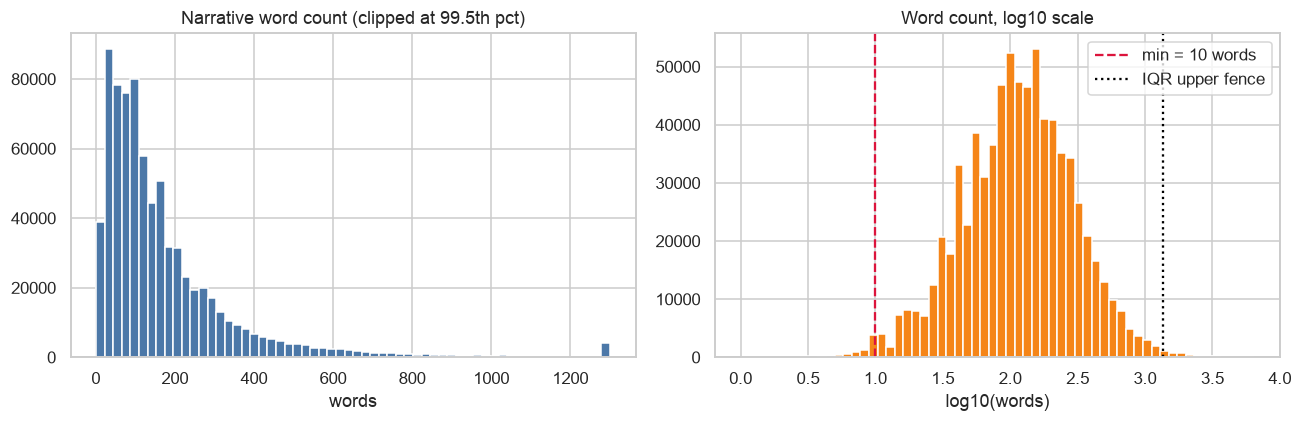

In [13]:
MIN_REAL_WORDS = 10
df["text_usable"] = has_text & (df["real_word_count"] >= MIN_REAL_WORDS)

# IQR fences on log word count flag the extreme tail (flag only, nothing is removed)
lw = np.log1p(df.loc[df["text_usable"], "word_count"])
q1, q3 = lw.quantile([.25, .75])
upper_fence = q3 + 1.5 * (q3 - q1)
lower_fence = q1 - 1.5 * (q3 - q1)
df["long_outlier"] = df["text_usable"] & (np.log1p(df["word_count"]) > upper_fence)
df["short_outlier"] = df["text_usable"] & (np.log1p(df["word_count"]) < lower_fence)

print(f"Narratives present:            {int(has_text.sum()):,}")
print(f"Usable (>= {MIN_REAL_WORDS} real words):      {int(df['text_usable'].sum()):,}")
print(f"Too short / mostly redacted:   {int((has_text & ~df['text_usable']).sum()):,}")
print(f"Long-tail outliers (flagged):  {int(df['long_outlier'].sum()):,}  (> {np.expm1(upper_fence):,.0f} words)")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
wc = df.loc[has_text, "word_count"]
axes[0].hist(wc.clip(upper=wc.quantile(.995)), bins=60, color="#4C78A8")
axes[0].set_title("Narrative word count (clipped at 99.5th pct)")
axes[0].set_xlabel("words")
axes[1].hist(np.log10(wc.clip(lower=1)), bins=60, color="#F58518")
axes[1].axvline(np.log10(MIN_REAL_WORDS), color="crimson", ls="--", label=f"min = {MIN_REAL_WORDS} words")
axes[1].axvline(np.log10(max(np.expm1(upper_fence), 1)), color="black", ls=":", label="IQR upper fence")
axes[1].set_title("Word count, log10 scale")
axes[1].set_xlabel("log10(words)")
axes[1].legend()
savefig("03_narrative_length")
log_step("4.4 text_usable flag (no rows dropped)", df, f"{int(df['text_usable'].sum()):,} usable narratives")

### 4.5 Label taxonomy drift (`product`)
The CFPB renamed and merged product categories over time, so the same real-world product can appear under several labels in different years. If left alone, a routing model would treat the old and new names as different classes and learn the *year* instead of the *product*. The crosstab shows the drift. The mapping targets the CFPB's **current (2023+) product list**. Renames with a single successor are mapped directly. Old labels that the CFPB later *split* (`Credit card or prepaid card` 2017–2023, `Consumer Loan` 2012–2017, `Other financial service` 2014–2017) are assigned by their `sub_product`, whose values are disjoint between the successor products. Credit repair and debt settlement, wherever they were filed before 2023, go to `Debt or credit management`, where the CFPB files them today. Any label left without a successor would be flagged as legacy.

date_received,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
product,,,,,,,,,,,,,,,,
Bank account or service,0,2449,2616,2914,3537,4366,1348,0,0,0,0,0,0,0,0,0
Checking or savings account,0,0,0,0,0,0,2569,4143,4318,4823,5936,7557,10016,10498,16977,12103
Consumer Loan,0,393,613,1085,1561,1909,710,0,0,0,0,0,0,0,0,0
Credit card,240,3044,2668,2699,3399,4138,1454,0,0,0,0,0,4380,15154,18120,12909
Credit card or prepaid card,0,0,0,0,0,0,3069,4855,5204,6821,6352,7911,7142,0,0,0
Credit reporting,0,395,2875,5953,6828,8949,3207,0,0,0,0,0,0,0,0,0
Credit reporting or other personal consumer reports,0,0,0,0,0,0,0,0,0,0,0,0,80131,472090,958900,882077
"Credit reporting, credit repair services, or other personal consumer reports",0,0,0,0,0,0,14666,22372,27772,56590,61464,121092,128609,0,0,0
Debt collection,0,0,2174,7757,7948,8029,9580,10262,9291,10865,13935,11735,13540,31134,56332,43986


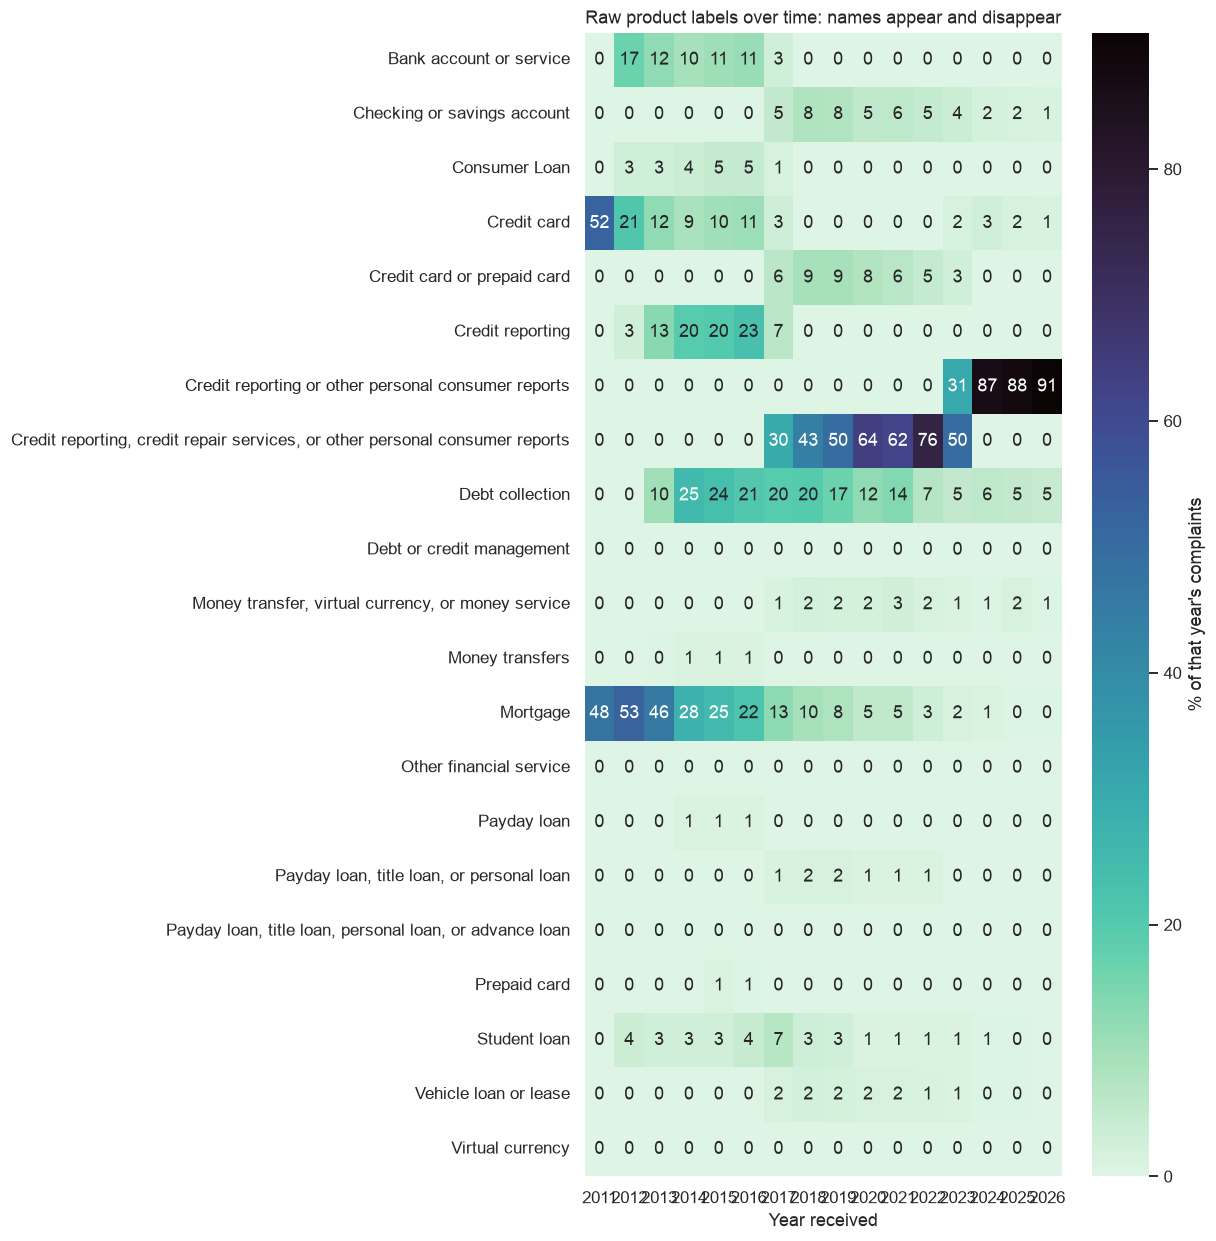

In [14]:
prod_year = pd.crosstab(df["product"], df["date_received"].dt.year)
display(prod_year)

share = prod_year.div(prod_year.sum(axis=0), axis=1) * 100
fig, ax = plt.subplots(figsize=(11, 0.45 * len(share) + 2))
sns.heatmap(share, cmap="mako_r", annot=len(share.columns) <= 16, fmt=".0f", cbar_kws={"label": "% of that year's complaints"}, ax=ax)
ax.set_xlabel("Year received")
ax.set_ylabel("")
ax.set_title("Raw product labels over time: names appear and disappear")
savefig("04_product_taxonomy_drift")

In [15]:
# Target: the CFPB's current (2023+) product list, so a routing model trained on old years predicts today's classes.
CREDIT_REPORTING = "Credit reporting"
CREDIT_CARD = "Credit card"
PREPAID = "Prepaid card"
PAYDAY = "Payday, title or personal loan"
BANK = "Checking or savings account"
MONEY = "Money transfer or virtual currency"
VEHICLE = "Vehicle loan or lease"
DEBT_MGMT = "Debt or credit management"

# Step 1: one-to-one renames (the old label has exactly one successor)
PRODUCT_HARMONIZATION = {
    "Credit reporting": CREDIT_REPORTING,
    "Credit reporting, credit repair services, or other personal consumer reports": CREDIT_REPORTING,
    "Credit reporting or other personal consumer reports": CREDIT_REPORTING,
    "Credit card": CREDIT_CARD,
    "Prepaid card": PREPAID,
    "Payday loan": PAYDAY,
    "Payday loan, title loan, or personal loan": PAYDAY,
    "Payday loan, title loan, personal loan, or advance loan": PAYDAY,
    "Bank account or service": BANK, "Checking or savings account": BANK,
    "Money transfers": MONEY, "Virtual currency": MONEY,
    "Money transfer, virtual currency, or money service": MONEY,
}

# Step 2: old labels that the CFPB later split. The sub-product says which current product the complaint belongs to
# (see the sub-product tables printed below: the sub-products of each merged label are disjoint).
SPLIT_BY_SUB_PRODUCT = {
    # 2017-04 to 2023-08 credit and prepaid cards shared one label; they are separate products again from 2023
    "Credit card or prepaid card": lambda sp: PREPAID if re.search(r"prepaid|gift|payroll|benefit|transit|wallet", sp, re.I)
                                              else CREDIT_CARD,
    # Consumer Loan (2012-2017) was split into vehicle loans and personal/installment/title/pawn loans
    "Consumer Loan": lambda sp: VEHICLE if sp.startswith("Vehicle") else PAYDAY,
    # Other financial service (2014-2017): its money services moved to the money-service product,
    # debt settlement and credit repair to Debt or credit management
    "Other financial service": lambda sp: DEBT_MGMT if sp in ("Debt settlement", "Credit repair") else MONEY,
}
# Step 3: sub-products that have moved to "Debt or credit management" since 2023, whatever their old product label
TO_DEBT_MGMT = {"Credit repair services", "Credit repair", "Debt settlement"}

for old in SPLIT_BY_SUB_PRODUCT:
    print(f"\n{old}: sub-products")
    display(df.loc[df["product"] == old, "sub_product"].value_counts().to_frame("n").head(10))

prod_raw = df["product"].astype(str)
sub = df["sub_product"].fillna("").astype(str)
product_clean = prod_raw.map(PRODUCT_HARMONIZATION)
for old, rule in SPLIT_BY_SUB_PRODUCT.items():
    m = prod_raw == old
    product_clean[m] = [rule(s) for s in sub[m]]
moved = sub.isin(TO_DEBT_MGMT)
product_clean[moved] = DEBT_MGMT
df["product_clean"] = product_clean.fillna(prod_raw)       # labels with no mapping keep their name
print(f"\nRows moved to '{DEBT_MGMT}' by sub-product: {int(moved.sum()):,}")
print(f"Distinct product labels: {df['product'].nunique()} raw -> {df['product_clean'].nunique()} harmonised")

unchanged = sorted(set(prod_raw.unique()) - set(PRODUCT_HARMONIZATION) - set(SPLIT_BY_SUB_PRODUCT))
print("Labels kept as they are (no rename needed):", unchanged)

# Data-driven legacy flag: a harmonised label whose last complaint is more than a year before the end of the data
last_year = df.groupby("product_clean")["date_received"].max().dt.year
max_year = int(df["date_received"].dt.year.max())
legacy_products = last_year[last_year < max_year - 1].index.tolist()
df["product_legacy"] = df["product_clean"].isin(legacy_products)
print(f"Legacy labels (no complaints after {max_year - 2}): {legacy_products or 'none'}")

display(df["product_clean"].value_counts().to_frame("n").assign(share=lambda t: t["n"] / t["n"].sum()))

# Check: after harmonisation every product should run continuously over time (no label switching on or off)
display(pd.crosstab(df["product_clean"], df["date_received"].dt.year))


Credit card or prepaid card: sub-products


,n
sub_product,
General-purpose credit card or charge card,31825
Store credit card,5664
Government benefit card,1821
General-purpose prepaid card,1670
Gift card,191
Payroll card,177
Student prepaid card,6



Consumer Loan: sub-products


,n
sub_product,
Vehicle loan,3596
Installment loan,1650
Vehicle lease,535
Personal line of credit,374
Title loan,105
Pawn loan,11



Other financial service: sub-products


,n
sub_product,
Debt settlement,65
Check cashing,53
Money order,29
Credit repair,21
Traveler’s/Cashier’s checks,15
Refund anticipation check,14
Foreign currency exchange,10



Rows moved to 'Debt or credit management' by sub-product: 3,273
Distinct product labels: 21 raw -> 11 harmonised
Labels kept as they are (no rename needed): ['Debt collection', 'Debt or credit management', 'Mortgage', 'Student loan', 'Vehicle loan or lease']
Legacy labels (no complaints after 2024): none


,n,share
product_clean,,
Credit reporting,2852946,0.815
Debt collection,236568,0.068
Credit card,105694,0.030
Checking or savings account,96170,0.027
Mortgage,91882,0.026
Money transfer or virtual currency,38697,0.011
Student loan,26687,0.008
Vehicle loan or lease,24756,0.007
"Payday, title or personal loan",16874,0.005


date_received,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
product_clean,,,,,,,,,,,,,,,,
Checking or savings account,0,2449,2616,2914,3537,4366,3917,4143,4318,4823,5936,7557,10016,10498,16977,12103
Credit card,240,3044,2668,2699,3399,4138,4364,4578,4843,5777,5540,7272,10949,15154,18120,12909
Credit reporting,0,395,2875,5953,6828,8949,17821,22305,27685,56477,61335,120790,208466,472090,958900,882077
Debt collection,0,0,2174,7757,7948,8029,9580,10262,9291,10865,13935,11735,13540,31134,56332,43986
Debt or credit management,0,0,0,3,25,41,86,89,115,141,163,335,379,526,866,623
Money transfer or virtual currency,0,0,96,252,361,392,708,1087,1011,1636,2750,2681,2647,3295,16697,5084
Mortgage,218,7561,9980,8581,8462,8435,6169,4925,4563,4844,5347,4582,4528,4222,4880,4585
"Payday, title or personal loan",0,119,209,683,850,995,936,899,895,844,855,1150,1373,1842,2645,2579
Prepaid card,0,0,0,72,354,247,271,277,361,1044,812,639,996,1261,1312,838


### 4.6 Build the targets and finish cleaning
The relief label follows the mapping from section 3.2. The remaining optional categorical columns get an explicit `Missing` category (decisions from 4.1) and are converted to the memory-efficient `category` dtype.

In [16]:
df["relief"] = df["company_response"].astype(object).map(RELIEF_MAP).astype("float64")

relief_table = (df["company_response"].value_counts(dropna=False).rename("n").to_frame()
                .assign(relief_label=lambda t: [RELIEF_MAP.get(i, np.nan) for i in t.index]))
display(relief_table)

print(f"Rows with a defined relief label: {int(df['relief'].notna().sum()):,} of {len(df):,}")
print(f"Overall monetary-relief rate among labelled rows: {df['relief'].mean():.2%}")

# Explicit categories for informative missingness (decisions in 4.1)
df["tags"] = df["tags"].fillna("None")
for c in present(["sub_product", "sub_issue", "company_public_response", "consumer_consent_provided",
                  "consumer_disputed", "submitted_via", "timely_response", "state", "zip3", "company"]):
    df[c] = df[c].fillna("Missing")

CAT_COLS = present(["product", "product_clean", "sub_product", "issue", "sub_issue", "company", "state", "zip3", "tags",
                    "consumer_consent_provided", "submitted_via", "company_public_response", "company_response",
                    "timely_response", "consumer_disputed"])
for c in CAT_COLS:
    df[c] = df[c].astype("category")

log_step("4.6 targets built, categories typed", df)
print(f"Cleaned frame: {df.shape[0]:,} rows x {df.shape[1]} columns | {df.memory_usage(deep=True).sum() / 1e9:.2f} GB")

,n,relief_label
company_response,,
Closed with explanation,2161612,0.000
Closed with non-monetary relief,1186456,0.000
In progress,95901,NaN
Closed with monetary relief,43537,1.000
Untimely response,6681,NaN
Closed,3523,0.000
Closed without relief,3461,0.000
Closed with relief,975,NaN
<NA>,4,NaN


Rows with a defined relief label: 3,398,589 of 3,502,150
Overall monetary-relief rate among labelled rows: 1.28%


Cleaned frame: 3,502,150 rows x 30 columns | 1.19 GB


## 5. Feature engineering for EDA
Calendar features (for drift and the time-based split), text-shape features (length, redaction, dollar amounts, shouting) and simple flags. These are exploratory features. Whether they enter a model is decided in section 6.9.

In [17]:
d = df["date_received"]
df["year"] = d.dt.year.astype("int16")
df["month"] = d.dt.month.astype("int8")
df["quarter"] = d.dt.quarter.astype("int8")
df["dow"] = d.dt.dayofweek.astype("int8")

tags_str = df["tags"].astype("string")
df["is_older_american"] = tags_str.str.contains("Older American", na=False)
df["is_servicemember"] = tags_str.str.contains("Servicemember", na=False)
df["has_narrative"] = df["narrative"].notna()

# Text-shape features, computed on usable narratives only
usable = df["text_usable"]
txt = df.loc[usable, "narrative"]


def add_text_feature(name, series):
    out = pd.Series(np.nan, index=df.index, dtype="float32")
    out.loc[series.index] = series.astype("float32")
    df[name] = out


add_text_feature("n_dollar", txt.str.count(r"\{\$"))                       # CFPB wraps amounts like {$250.00}
add_text_feature("n_exclaim", txt.str.count("!"))
add_text_feature("upper_share", txt.str.count(r"[A-Z]") / df.loc[usable, "char_len"])
df["xxxx_share"] = (df["xxxx_count"] / df["word_count"]).astype("float32")

NUM_FEATURES = ["days_to_company", "char_len", "word_count", "xxxx_count", "xxxx_share",
                "n_dollar", "upper_share", "n_exclaim"]
print("Engineered features:", ["year", "month", "quarter", "dow", "is_older_american", "is_servicemember",
                               "has_narrative", "n_dollar", "n_exclaim", "upper_share", "xxxx_share"])
display(df[NUM_FEATURES].describe().T)

Engineered features: ['year', 'month', 'quarter', 'dow', 'is_older_american', 'is_servicemember', 'has_narrative', 'n_dollar', 'n_exclaim', 'upper_share', 'xxxx_share']


,count,mean,std,min,25%,50%,75%,max
days_to_company,"3,500,745.000",0.611,5.568,0.000,0.000,0.000,0.000,"1,748.000"
char_len,"766,154.000","1,023.857","1,282.411",5.000,348.000,672.000,"1,224.000","32,785.000"
word_count,"766,154.000",177.773,220.772,1.000,61.000,117.000,215.000,"6,469.000"
xxxx_count,"766,154.000",14.190,38.722,0.000,0.000,4.000,14.000,"4,306.000"
xxxx_share,"766,154.000",0.073,0.124,0.000,0.000,0.031,0.081,1.000
n_dollar,"758,548.000",0.700,2.327,0.000,0.000,0.000,0.000,380.000
upper_share,"758,548.000",0.102,0.143,0.000,0.030,0.054,0.103,0.877
n_exclaim,"758,548.000",0.197,1.490,0.000,0.000,0.000,0.000,368.000


## 6. Exploratory Data Analysis
Analysis frames used below:
- `df` is the full cleaned data. It is used for volume trends and for the narrative opt-in question.
- `df_text` has usable narratives only. It is used for text and routing questions.
- `df_rel` is `df_text` rows that also have a defined relief label. It is used for everything about relief.

### 6.1 Overview: volume, opt-in and structure

,rows,share_of_all
cleaned (all complaints),3502150,1.000
with a narrative,766154,0.219
usable narrative (df_text),758548,0.217
usable narrative + relief label (df_rel),756266,0.216


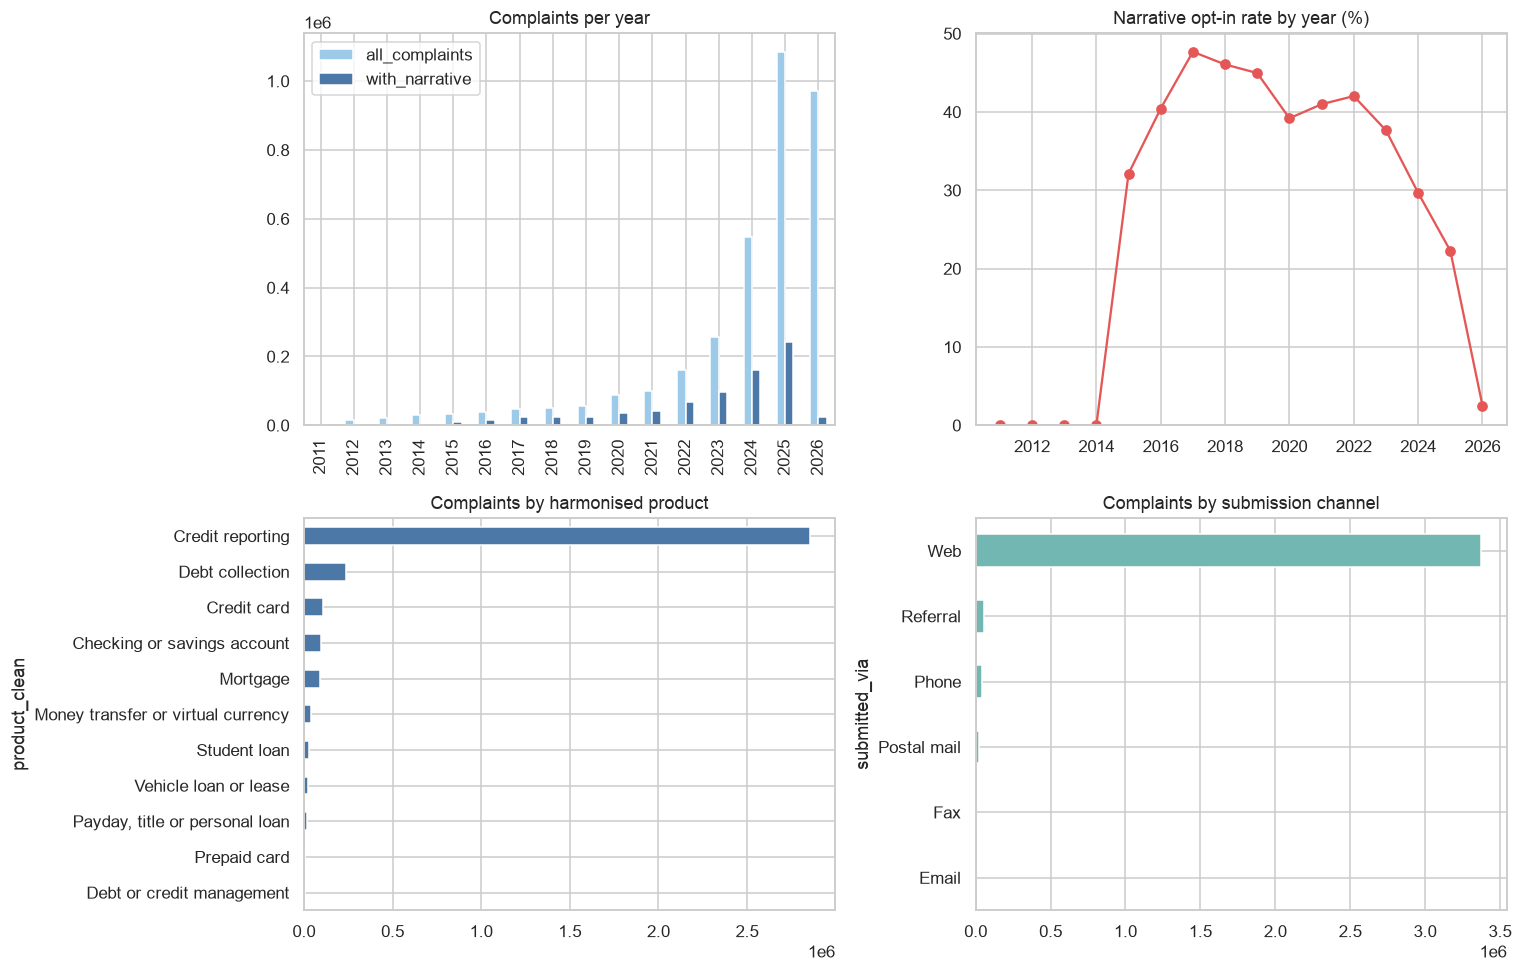

In [18]:
df_text = df[df["text_usable"]].copy()
df_rel = df_text[df_text["relief"].notna()].copy()
OVERALL_RELIEF = df_rel["relief"].mean()

sizes = pd.DataFrame({"rows": [len(df), int(df["has_narrative"].sum()), len(df_text), len(df_rel)]},
                     index=["cleaned (all complaints)", "with a narrative", "usable narrative (df_text)",
                            "usable narrative + relief label (df_rel)"])
sizes["share_of_all"] = sizes["rows"] / len(df)
display(sizes)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
yr = df.groupby("year").agg(all_complaints=("complaint_id", "size"), with_narrative=("has_narrative", "sum"))
yr.plot(kind="bar", ax=axes[0, 0], color=["#9ecae9", "#4C78A8"])
axes[0, 0].set_title("Complaints per year")
axes[0, 0].set_xlabel("")

(yr["with_narrative"] / yr["all_complaints"] * 100).plot(marker="o", ax=axes[0, 1], color="#E45756")
axes[0, 1].set_title("Narrative opt-in rate by year (%)")
axes[0, 1].set_xlabel("")
axes[0, 1].set_ylim(bottom=0)

df["product_clean"].value_counts().sort_values().plot(kind="barh", ax=axes[1, 0], color="#4C78A8")
axes[1, 0].set_title("Complaints by harmonised product")

df["submitted_via"].value_counts().sort_values().plot(kind="barh", ax=axes[1, 1], color="#72B7B2")
axes[1, 1].set_title("Complaints by submission channel")
savefig("05_overview")

### 6.2 Univariate analysis: every numeric feature
Each numeric feature gets summary statistics (including skew and kurtosis) and a histogram. Strongly right-skewed features are drawn on a log scale.

,count,mean,std,min,median,max,skew,kurt,share_zero
days_to_company,"758,548.000",0.831,6.625,0.000,0.000,"1,748.000",57.354,"10,216.307",0.932
char_len,"758,548.000","1,033.316","1,285.239",39.000,679.000,"32,785.000",6.495,85.373,0.000
word_count,"758,548.000",179.423,221.241,10.000,119.000,"6,469.000",6.486,85.745,0.000
xxxx_count,"758,548.000",14.270,38.815,0.000,4.000,"4,306.000",21.218,"1,225.673",0.300
xxxx_share,"758,548.000",0.072,0.121,0.000,0.031,0.990,3.179,12.065,0.300
n_dollar,"758,548.000",0.700,2.327,0.000,0.000,380.000,16.601,"1,288.385",0.776
upper_share,"758,548.000",0.102,0.143,0.000,0.054,0.877,3.265,11.576,0.002
n_exclaim,"758,548.000",0.197,1.490,0.000,0.000,368.000,55.091,"7,875.653",0.930


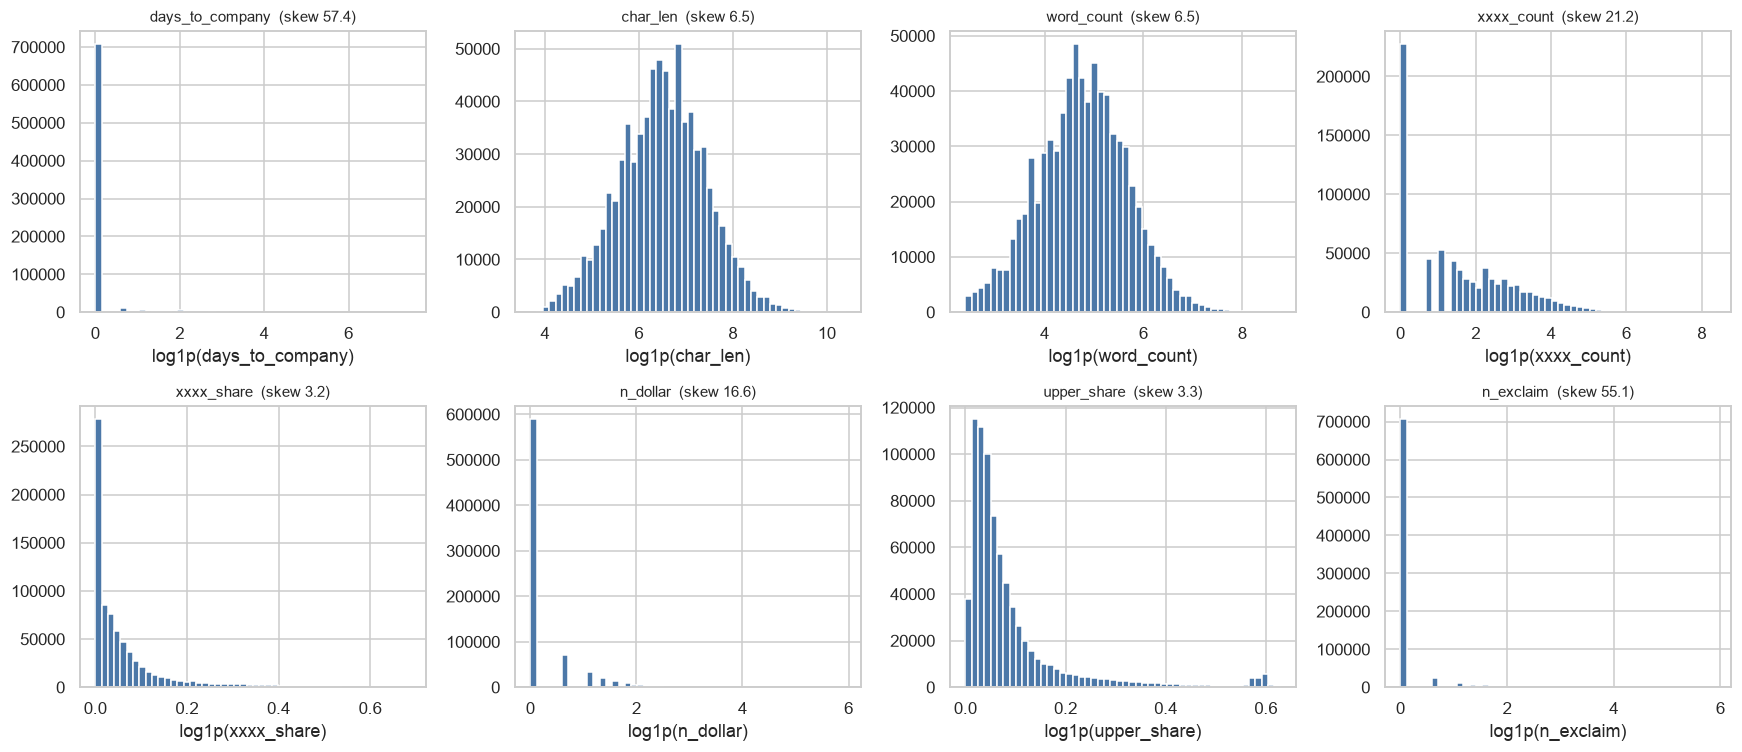

In [19]:
num_summary = df_text[NUM_FEATURES].agg(["count", "mean", "std", "min", "median", "max", "skew", "kurt"]).T
num_summary["share_zero"] = [(df_text[c] == 0).mean() for c in NUM_FEATURES]
display(num_summary)

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, c in zip(axes.ravel(), NUM_FEATURES):
    x = df_text[c].dropna()
    if x.skew() > 2 and (x >= 0).all():
        ax.hist(np.log1p(x), bins=50, color="#4C78A8")
        ax.set_xlabel(f"log1p({c})")
    else:
        ax.hist(x, bins=50, color="#4C78A8")
        ax.set_xlabel(c)
    ax.set_title(f"{c}  (skew {x.skew():.1f})", fontsize=10)
savefig("06_numeric_histograms")

### 6.3 Univariate analysis: every categorical feature
Cardinality and concentration first (high-cardinality columns need different handling than binary ones), then bar charts of the most frequent levels.

,n_levels,top_level,top_level_share,top10_share
feature,,,,
product_clean,11,Credit reporting,0.648,0.998
sub_product,85,Credit reporting,0.635,0.866
issue,172,Incorrect information on your report,0.311,0.782
sub_issue,266,Information belongs to someone else,0.180,0.707
company,4552,"EQUIFAX, INC",0.211,0.707
state,63,TX,0.126,0.662
zip3,877,300,0.021,0.168
tags,4,None,0.903,1.000
submitted_via,1,Web,1.000,1.000


Constant among narrative complaints: {'submitted_via': 'Web'}
submitted_via among all complaints: {'Web': 0.9637, 'Referral': 0.0158, 'Phone': 0.0126, 'Postal mail': 0.0063, 'Fax': 0.0015, 'Email': 0.0}


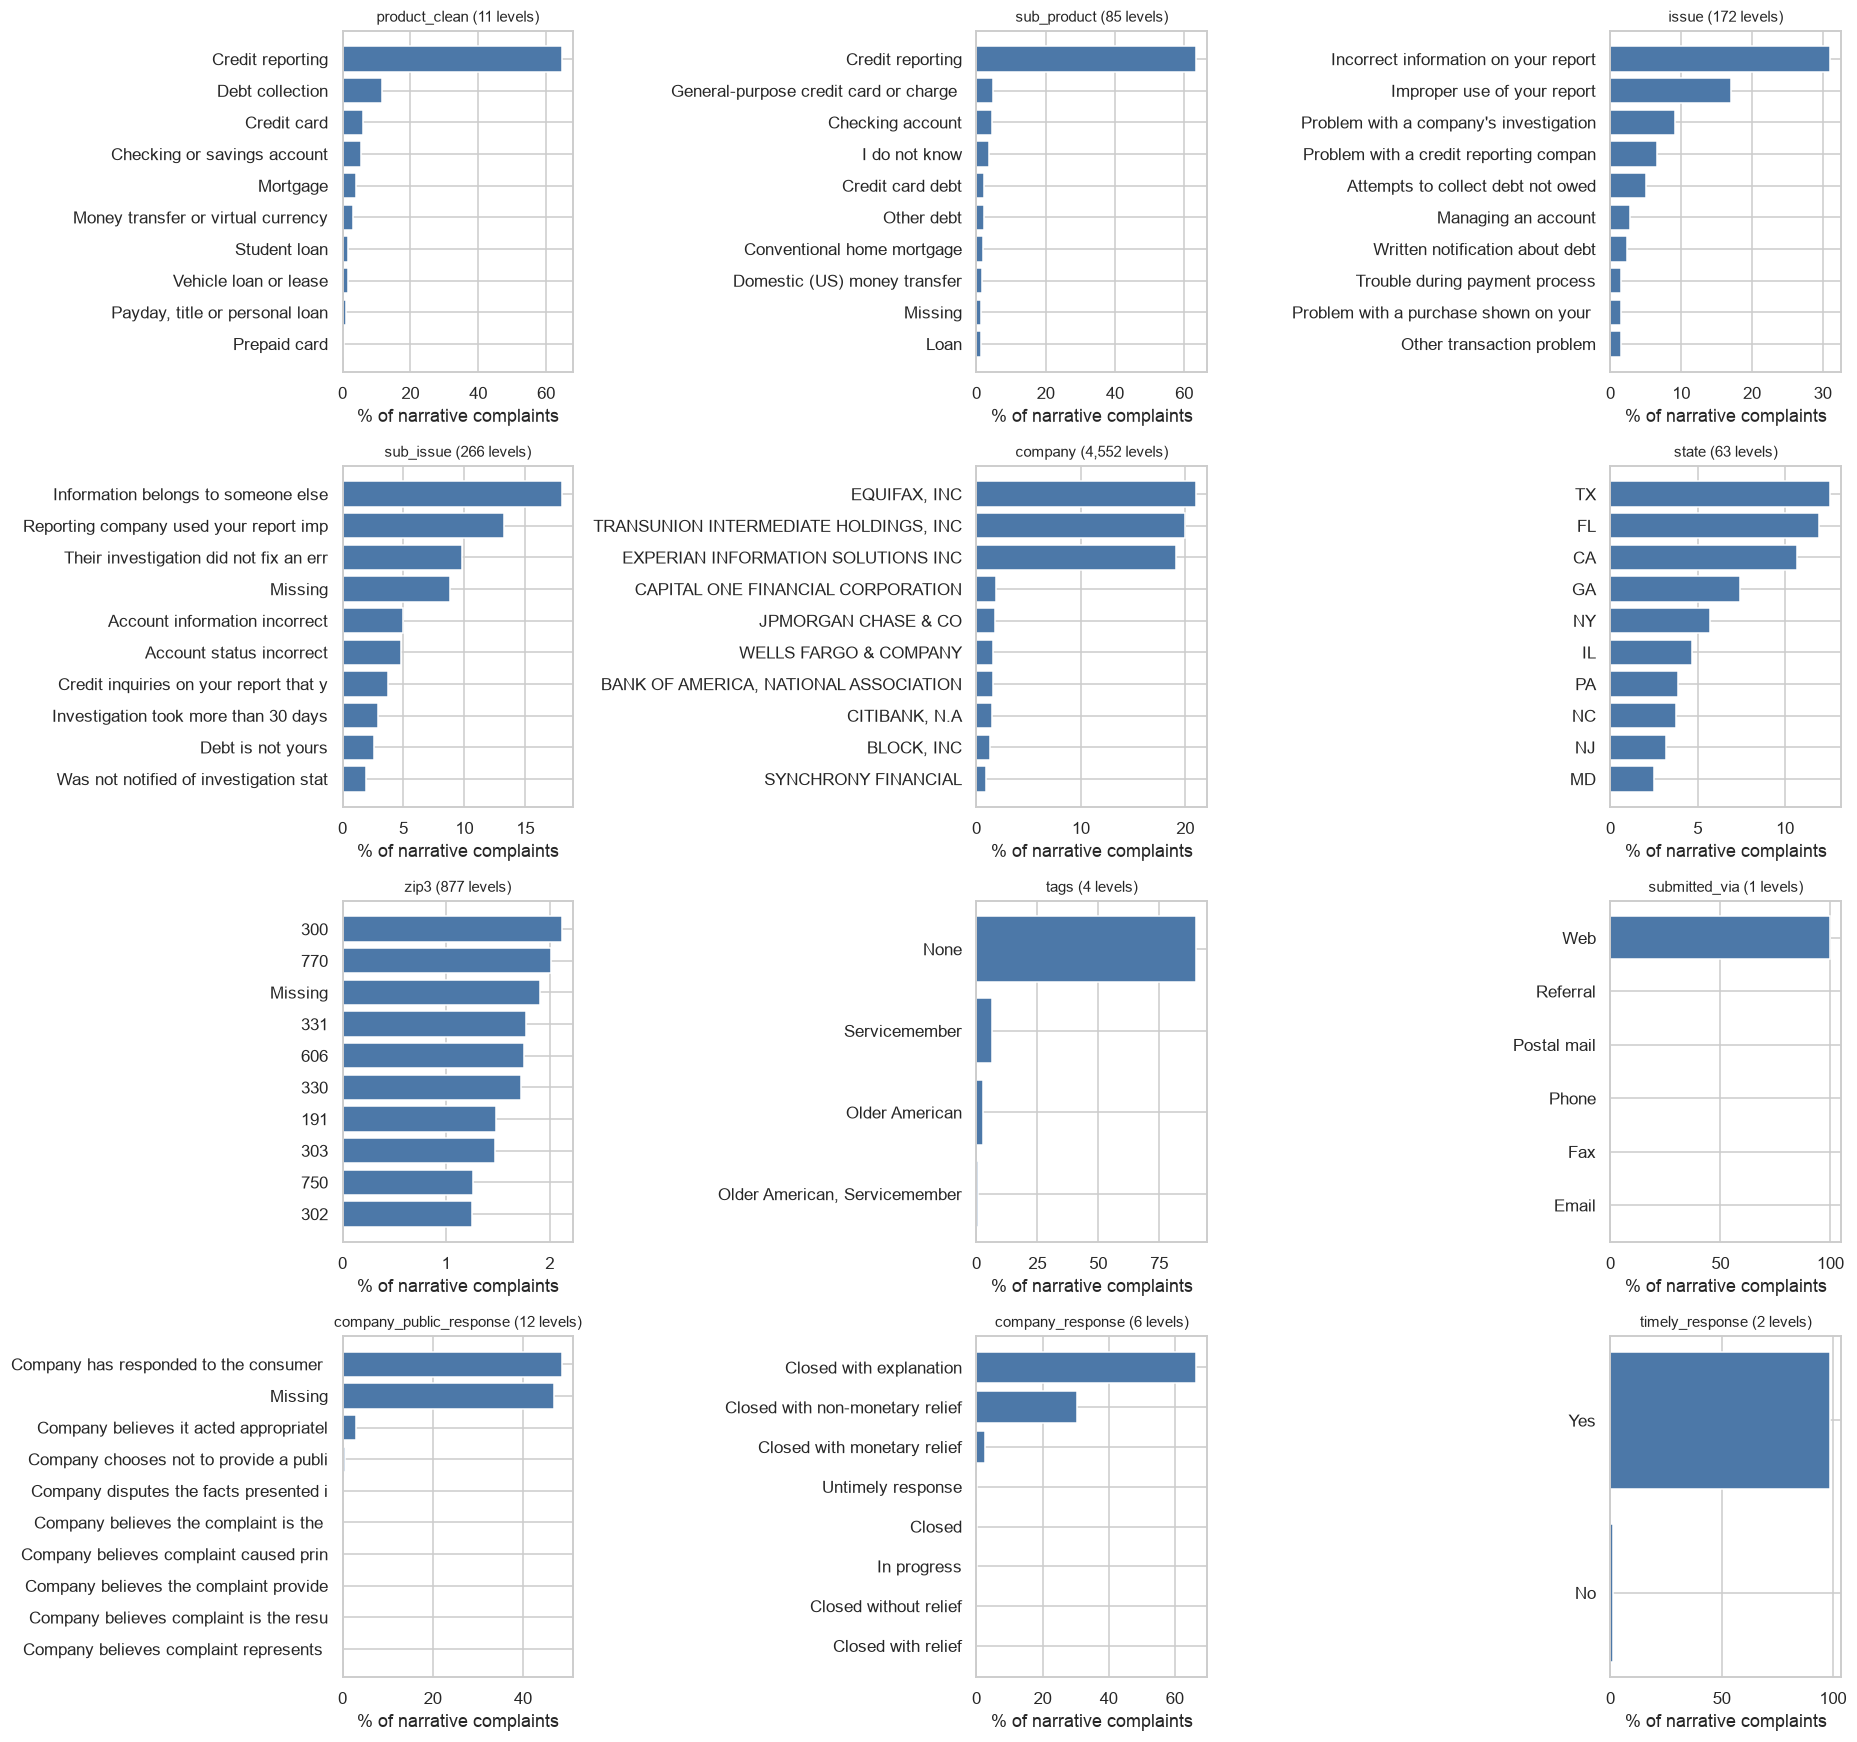

In [20]:
CAT_FEATURES = present(["product_clean", "sub_product", "issue", "sub_issue", "company", "state", "zip3", "tags",
                        "consumer_consent_provided", "submitted_via", "company_public_response", "company_response",
                        "timely_response", "consumer_disputed"])

card = []
for c in CAT_FEATURES:
    vc = df_text[c].value_counts()
    card.append({"feature": c, "n_levels": int(df_text[c].nunique()), "top_level": str(vc.index[0])[:45],
                 "top_level_share": vc.iloc[0] / vc.sum(), "top10_share": vc.head(10).sum() / vc.sum()})
cardinality = pd.DataFrame(card).set_index("feature")
display(cardinality)

# Constant in the narrative subset? (e.g. narratives can only be written in the web form)
constant_in_text = [c for c in CAT_FEATURES if df_text[c].nunique() < 2]
print("Constant among narrative complaints:", {c: str(df_text[c].iloc[0]) for c in constant_in_text} or "none")
print("submitted_via among all complaints:", df["submitted_via"].value_counts(normalize=True).round(4).to_dict())

n_rows_fig = int(np.ceil(len(CAT_FEATURES) / 3))
fig, axes = plt.subplots(n_rows_fig, 3, figsize=(17, 4 * n_rows_fig))
for ax, c in zip(axes.ravel(), CAT_FEATURES):
    vc = df_text[c].value_counts(normalize=True).head(10).sort_values() * 100
    ax.barh([str(i)[:38] for i in vc.index], vc.values, color="#4C78A8")
    ax.set_title(f"{c} ({df_text[c].nunique():,} levels)", fontsize=10)
    ax.set_xlabel("% of narrative complaints")
for ax in axes.ravel()[len(CAT_FEATURES):]:
    ax.axis("off")
savefig("07_categorical_bars")

### 6.4 The relief target: balance and where it varies
Relief rates by group with 95% Wilson confidence intervals. Groups with few complaints are hidden (minimum group size shown in each title) so that noise is not mistaken for signal. The dashed line is the overall rate.

,n,share
relief,,
no monetary relief,736536,0.974
monetary relief,19730,0.026


Imbalance ratio (majority : minority) = 37.3 : 1


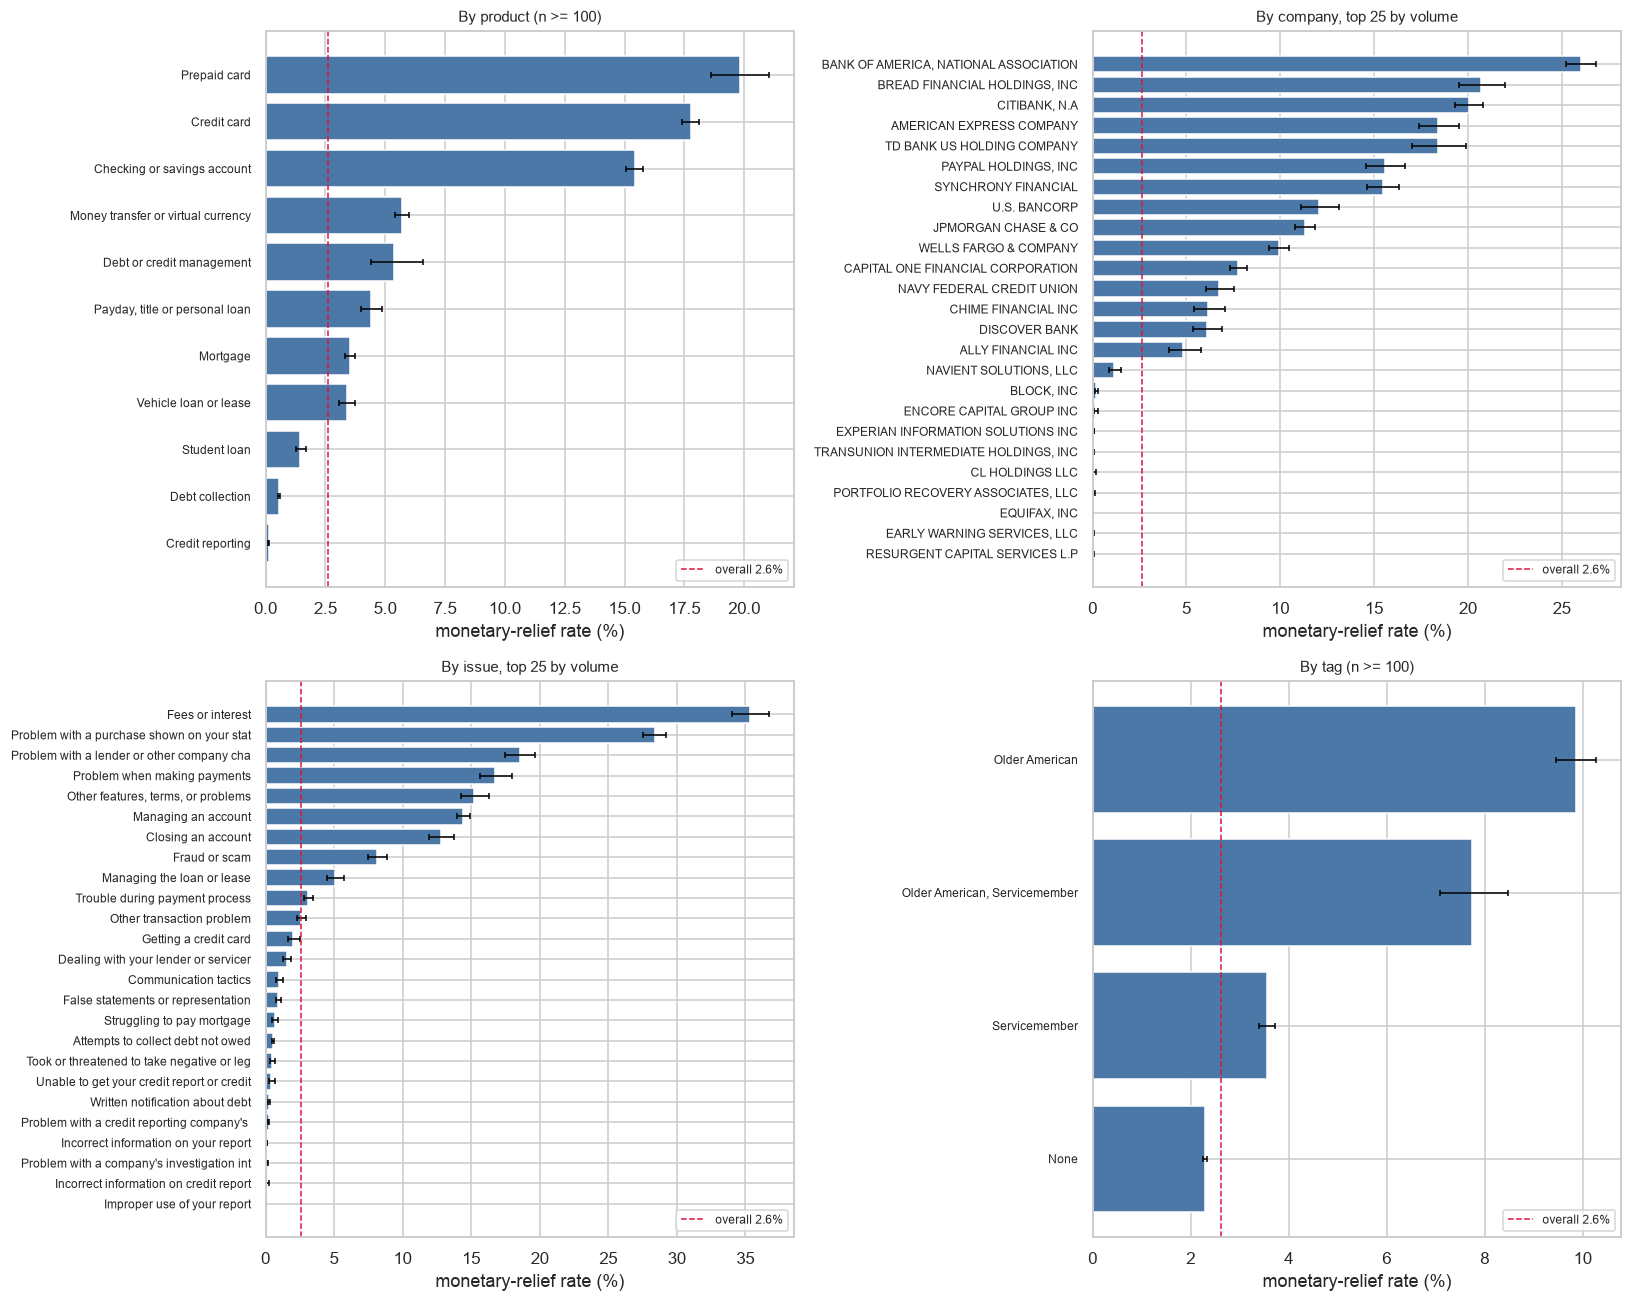

In [21]:
def wilson_ci(k, n, z=1.96):
    k = np.asarray(k, dtype=float)
    n = np.asarray(n, dtype=float)
    p = k / n
    denom = 1 + z ** 2 / n
    centre = (p + z ** 2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / denom
    return centre - half, centre + half


def rate_table(frame, col, min_n=100):
    g = frame.groupby(col, observed=True)["relief"].agg(n="size", relief_n="sum")
    g = g[g["n"] >= min_n].copy()
    g["rate"] = g["relief_n"] / g["n"]
    g["ci_lo"], g["ci_hi"] = wilson_ci(g["relief_n"], g["n"])
    return g.sort_values("rate")


def plot_rate(tbl, title, ax):
    y = np.arange(len(tbl))
    ax.barh(y, tbl["rate"] * 100, color="#4C78A8")
    ax.errorbar(tbl["rate"] * 100, y,
                xerr=[(tbl["rate"] - tbl["ci_lo"]).to_numpy() * 100, (tbl["ci_hi"] - tbl["rate"]).to_numpy() * 100],
                fmt="none", ecolor="black", elinewidth=1, capsize=2)
    ax.axvline(OVERALL_RELIEF * 100, color="crimson", ls="--", lw=1, label=f"overall {OVERALL_RELIEF:.1%}")
    ax.set_yticks(y)
    ax.set_yticklabels([str(i)[:42] for i in tbl.index], fontsize=8)
    ax.set_xlabel("monetary-relief rate (%)")
    ax.set_title(title, fontsize=10)
    ax.legend(fontsize=8, loc="lower right")


balance = df_rel["relief"].value_counts().rename(index={0.0: "no monetary relief", 1.0: "monetary relief"}).to_frame("n")
balance["share"] = balance["n"] / balance["n"].sum()
display(balance)
print(f"Imbalance ratio (majority : minority) = {balance['n'].max() / balance['n'].min():.1f} : 1")

top_companies = df_rel["company"].value_counts().head(25).index
top_issues = df_rel["issue"].value_counts().head(25).index
panels = [
    (rate_table(df_rel, "product_clean", 100), "By product (n >= 100)"),
    (rate_table(df_rel[df_rel["company"].isin(top_companies)], "company", 100), "By company, top 25 by volume"),
    (rate_table(df_rel[df_rel["issue"].isin(top_issues)], "issue", 100), "By issue, top 25 by volume"),
    (rate_table(df_rel, "submitted_via", 100), "By submission channel (n >= 100)"),
    (rate_table(df_rel, "tags", 100), "By tag (n >= 100)"),
] + ([(rate_table(df_rel, "consumer_consent_provided", 100), "By consent flag (n >= 100)")]
      if "consumer_consent_provided" in df_rel else [])
panels = [(t, ttl) for t, ttl in panels if len(t) >= 2]    # a single-level feature (e.g. constant consent flag) has nothing to compare
fig, axes = plt.subplots(int(np.ceil(len(panels) / 2)), 2, figsize=(15, 6 * int(np.ceil(len(panels) / 2))), squeeze=False)
for ax, (tbl, title) in zip(axes.ravel(), panels):
    plot_rate(tbl, title, ax)
for ax in axes.ravel()[len(panels):]:
    ax.axis("off")
savefig("08_relief_rate_by_group")

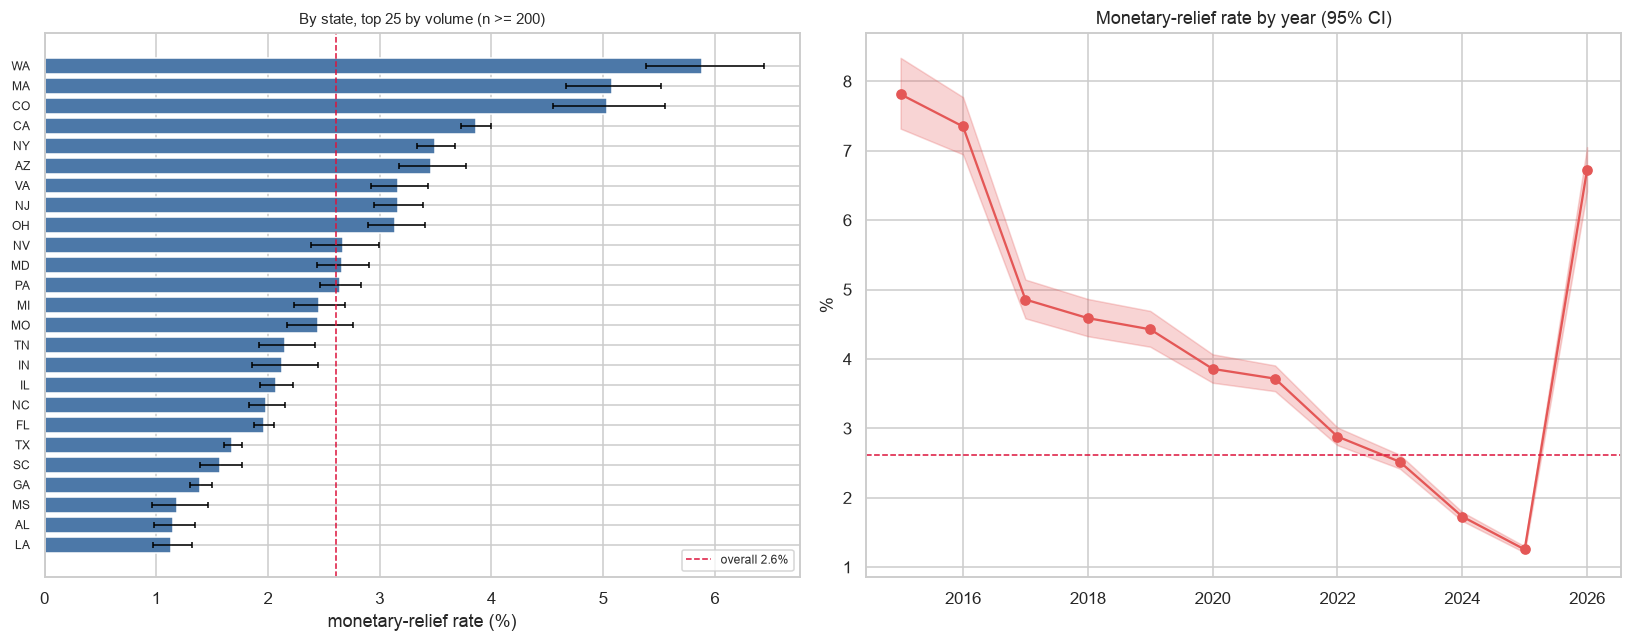

,n,rate
year,,
2015,10649,0.078
2016,15376,0.073
2017,22755,0.049
2018,23386,0.046
2019,24443,0.044
2020,33991,0.039
2021,40174,0.037
2022,66550,0.029
2023,95770,0.025


In [22]:
# By state (largest 25 states by volume) and by year
state_tbl = rate_table(df_rel[df_rel["state"].isin(df_rel["state"].value_counts().head(25).index)], "state", 200)
year_tbl = rate_table(df_rel, "year", 100).sort_index()

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
plot_rate(state_tbl, "By state, top 25 by volume (n >= 200)", axes[0])
axes[1].plot(year_tbl.index, year_tbl["rate"] * 100, marker="o", color="#E45756")
axes[1].fill_between(year_tbl.index, year_tbl["ci_lo"] * 100, year_tbl["ci_hi"] * 100, alpha=.25, color="#E45756")
axes[1].axhline(OVERALL_RELIEF * 100, color="crimson", ls="--", lw=1)
axes[1].set_title("Monetary-relief rate by year (95% CI)")
axes[1].set_ylabel("%")
savefig("09_relief_by_state_and_year")
display(year_tbl[["n", "rate"]])

**What 6.4 shows.**
- Monetary relief is rare: **2.6% of labelled narrative complaints (about 37:1)**.
- The **product** sets the base rate: prepaid card about 20%, credit card about 18%, checking/savings about 15%, debt collection 0.5%, credit reporting 0.1%. Credit reporting is two thirds of the narratives but almost never ends in money back.
- **Company** spreads rates even further: the large banks and card issuers (Bank of America about 26%, Citibank, Amex, Synchrony) are far above the credit bureaus and debt buyers (about 0%).
- By issue, *Fees or interest* (about 35%) and *Problem with a purchase shown on your statement* (about 28%) lead.
- Older Americans get relief about four times as often as untagged consumers.
- The year panel shows a steep downward trend, which section 6.8 explains.

### 6.5 Numeric features vs the relief target (Pearson and other statistics)
- **Pearson r** with the 0/1 target is the point-biserial correlation (linear association).
- **Spearman rho** captures monotonic association and is robust to the heavy skew seen above.
- **Mann-Whitney U with rank-biserial effect size** compares the two groups without assuming normality. With this many rows p-values are tiny for almost anything, so the **effect size** is what ranks features. Rank-biserial is positive when relief complaints tend to have larger values.

,n,pearson_r,pearson_p,spearman_rho,rank_biserial,mannwhitney_p,median_relief,median_no_relief
feature,,,,,,,,
n_dollar,300000,0.110,0.000,0.171,0.451,0.000,1.000,0.000
word_count,300000,0.061,0.000,0.091,0.331,0.000,200.000,117.000
char_len,300000,0.053,0.000,0.085,0.307,0.000,"1,097.500",670.000
xxxx_count,300000,-0.009,0.000,0.056,0.200,0.000,7.000,4.000
xxxx_share,300000,-0.035,0.000,0.020,0.073,0.000,0.036,0.030
days_to_company,300000,0.016,0.000,0.036,0.056,0.000,0.000,0.000
n_exclaim,300000,0.015,0.000,0.025,0.039,0.000,0.000,0.000
upper_share,300000,-0.040,0.000,-0.005,-0.017,0.009,0.055,0.054


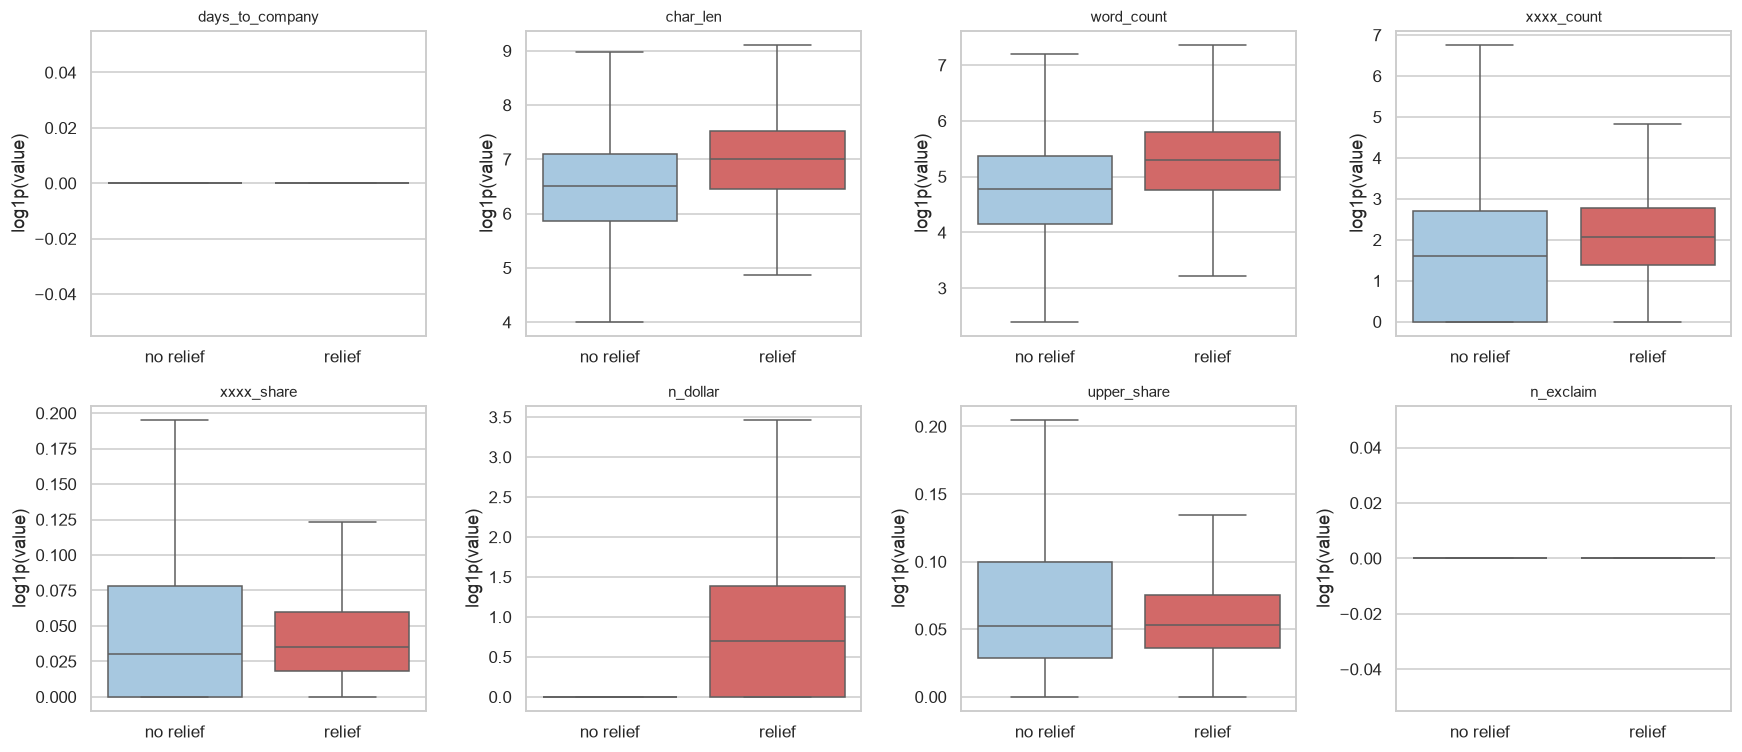

In [23]:
samp = df_rel.sample(min(len(df_rel), 300_000), random_state=RANDOM_STATE)
rows = []
for c in NUM_FEATURES:
    x = samp[[c, "relief"]].dropna()
    if x[c].nunique() < 2 or x["relief"].nunique() < 2:
        continue
    r, p_r = stats.pearsonr(x[c], x["relief"])
    rho, p_s = stats.spearmanr(x[c], x["relief"])
    a, b = x.loc[x["relief"] == 1, c], x.loc[x["relief"] == 0, c]
    u, p_u = stats.mannwhitneyu(a, b, alternative="two-sided")
    rows.append({"feature": c, "n": len(x), "pearson_r": r, "pearson_p": p_r, "spearman_rho": rho,
                 "rank_biserial": 2 * u / (len(a) * len(b)) - 1, "mannwhitney_p": p_u,
                 "median_relief": a.median(), "median_no_relief": b.median()})
num_vs_relief = pd.DataFrame(rows).set_index("feature").sort_values("rank_biserial", key=lambda s: s.abs(), ascending=False)
display(num_vs_relief)

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, c in zip(axes.ravel(), NUM_FEATURES):
    plot_df = samp[[c, "relief"]].dropna()
    plot_df = plot_df.assign(value=np.log1p(plot_df[c].clip(lower=0)),
                             outcome=plot_df["relief"].map({0.0: "no relief", 1.0: "relief"}))
    sns.boxplot(data=plot_df, x="outcome", y="value", ax=ax, showfliers=False, palette=["#9ecae9", "#E45756"], hue="outcome", legend=False)
    ax.set_title(c, fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("log1p(value)")
savefig("10_numeric_by_relief")

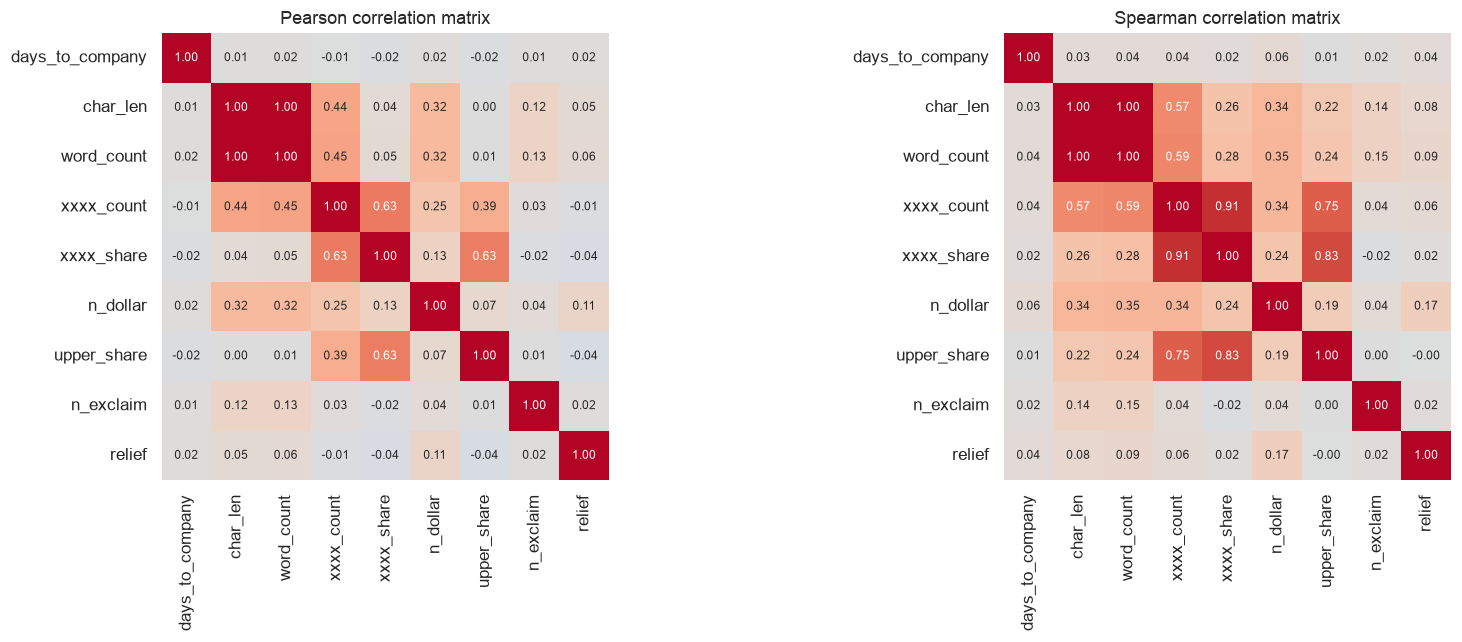

,feature_a,feature_b,pearson_r
10,char_len,word_count,0.996


In [24]:
corr_cols = NUM_FEATURES + ["relief"]
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, method in zip(axes, ["pearson", "spearman"]):
    cm = samp[corr_cols].corr(method=method)
    sns.heatmap(cm, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True, cbar=False, ax=ax,
                annot_kws={"size": 8})
    ax.set_title(f"{method.title()} correlation matrix")
savefig("11_correlation_heatmaps")

# Which numeric features are redundant with each other? (collinearity matters for the models in the next step)
cm = samp[NUM_FEATURES].corr()
pairs = (cm.where(np.triu(np.ones(cm.shape), k=1).astype(bool)).stack().rename("pearson_r")
         .reset_index().rename(columns={"level_0": "feature_a", "level_1": "feature_b"}))
display(pairs.loc[pairs["pearson_r"].abs() >= 0.7].sort_values("pearson_r", key=lambda s: s.abs(), ascending=False))

**What 6.5 shows.** Every numeric feature is statistically significant (p < 0.01) because n = 300k, so effect size is what matters. Relief complaints are **longer** (median 200 vs 117 words, rank-biserial 0.33) and much **more likely to quote a dollar amount** (`n_dollar`, rank-biserial 0.45, the largest effect). Pearson r stays small (0.11 at most) because the features are heavily skewed and the target is rare. Spearman is about 1.5× larger, which shows the relationships are monotonic but not linear (log transforms or tree models will help). Shouting (`upper_share`), exclamation marks and the redaction share are negligible. `char_len` and `word_count` are almost perfectly collinear (r = 0.996), so only one should be kept.

### 6.6 Categorical features vs the targets (chi-square, Cramér's V, mutual information)
For categorical features the Pearson coefficient does not apply, so association strength is measured with a **chi-square test of independence** and **bias-corrected Cramér's V** (0 = independent, 1 = perfectly associated), plus **mutual information** in bits. High-cardinality columns (company, issue, ZIP prefix, ...) are reduced to their 30 most frequent levels plus "Other" so that expected counts stay valid.

Association is computed twice: against **relief** (task 2) and against **product** (task 1). Expect `issue`/`sub_issue`/`sub_product` to be strongly tied to product: they are children of it in the CFPB taxonomy.

,cramers_v_relief,chi2_relief,dof,p_relief,mi_bits_relief,cramers_v_product
feature,,,,,,
company_response,1.000,"400,000.000",3,0.000,0.174,0.264
issue,0.363,"52,809.311",30,0.000,0.056,0.716
product_clean,0.339,"46,088.573",10,0.000,0.054,NaN
company,0.334,"44,528.894",30,0.000,0.053,0.468
sub_product,0.329,"43,336.936",30,0.000,0.053,0.873
sub_issue,0.321,"41,145.463",30,0.000,0.049,0.512
tags,0.082,"2,661.017",3,0.000,0.003,0.136
state,0.065,"1,709.117",30,0.000,0.003,0.061
zip3,0.044,795.058,30,0.000,0.002,0.046


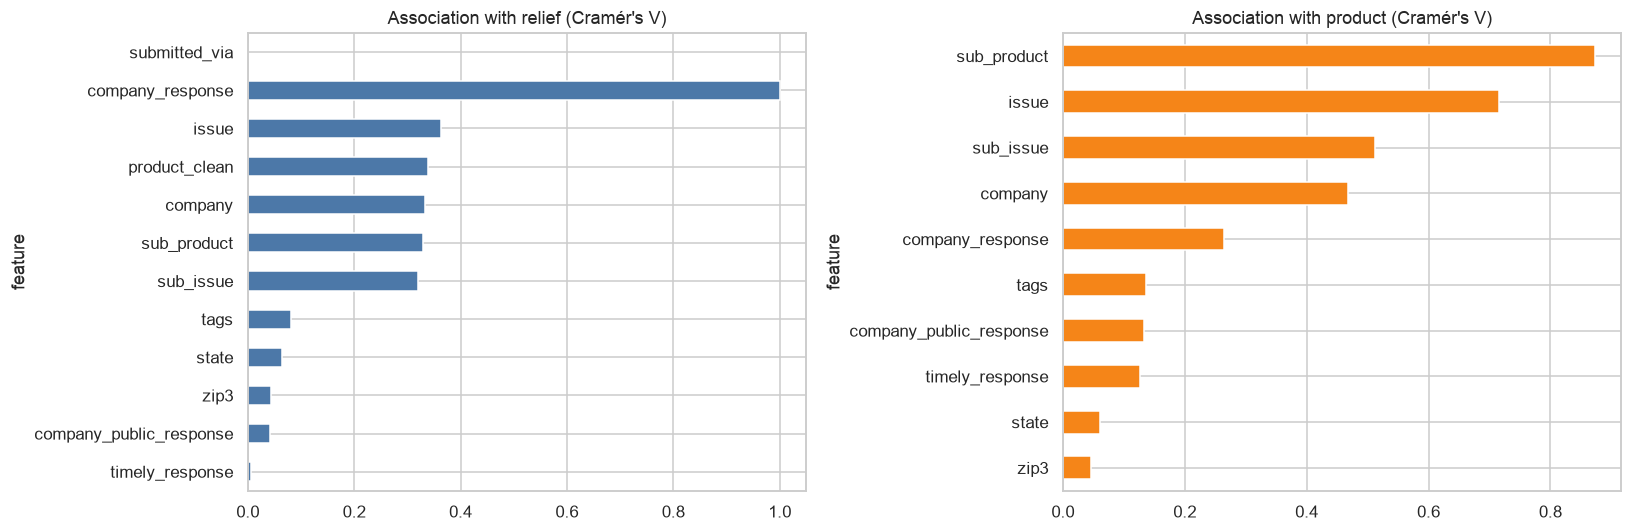

In [25]:
def lump(series, k=30):
    s = series.astype("string").fillna("Missing")
    keep = s.value_counts().nlargest(k).index
    return s.where(s.isin(keep), "Other").astype(str)


def cramers_v(x, y):
    ct = pd.crosstab(x, y)
    chi2_stat, p, dof, _ = stats.chi2_contingency(ct, correction=False)
    n = ct.to_numpy().sum()
    r, k = ct.shape
    phi2 = max(0.0, chi2_stat / n - (k - 1) * (r - 1) / (n - 1))
    r_c, k_c = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    denom = min(k_c - 1, r_c - 1)
    v = np.sqrt(phi2 / denom) if denom > 0 else np.nan
    return v, chi2_stat, p, dof


assoc_sample = df_rel.sample(min(len(df_rel), 400_000), random_state=RANDOM_STATE)
y_relief = assoc_sample["relief"].astype(int).astype(str)
y_product = assoc_sample["product_clean"].astype(str)

rows = []
for c in CAT_FEATURES:
    x = lump(assoc_sample[c])
    v_r, chi_r, p_r, dof_r = cramers_v(x, y_relief)
    row = {"feature": c, "cramers_v_relief": v_r, "chi2_relief": chi_r, "dof": dof_r, "p_relief": p_r,
           "mi_bits_relief": mutual_info_score(x, y_relief) / np.log(2)}
    if c != "product_clean":
        v_p, _, _, _ = cramers_v(x, y_product)
        row["cramers_v_product"] = v_p
    rows.append(row)
cat_assoc = pd.DataFrame(rows).set_index("feature").sort_values("cramers_v_relief", ascending=False)
display(cat_assoc)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
cat_assoc["cramers_v_relief"].sort_values().plot(kind="barh", ax=axes[0], color="#4C78A8")
axes[0].set_title("Association with relief (Cramér's V)")
cat_assoc["cramers_v_product"].dropna().sort_values().plot(kind="barh", ax=axes[1], color="#F58518")
axes[1].set_title("Association with product (Cramér's V)")
savefig("12_categorical_association")

**What 6.6 shows.** For **relief**, the strongest known-at-filing associations are `issue`, `product_clean`, `company`, `sub_product` and `sub_issue` (bias-corrected Cramér's V about 0.32–0.36). `tags` (0.08) and geography (`state` 0.07, `zip3` 0.04) are weak. For **routing**, `sub_product` (V = 0.87) and `issue` (0.72) are almost determined by the product. They are children of it in the taxonomy, so they must not be used as inputs to the routing model. `submitted_via` is constant (Web) for narrative complaints. `company_response` scores V = 1 only because it *defines* the target.

### 6.7 Text EDA: what the narratives look like and what separates the classes
Length by product and by outcome, then the vocabulary that characterises each product (TF-IDF lift versus all complaints) and the terms most associated with relief (chi-square). Vectorisation runs on a 100,000-row random sample to keep memory manageable. Redaction tokens are removed from the vocabulary.

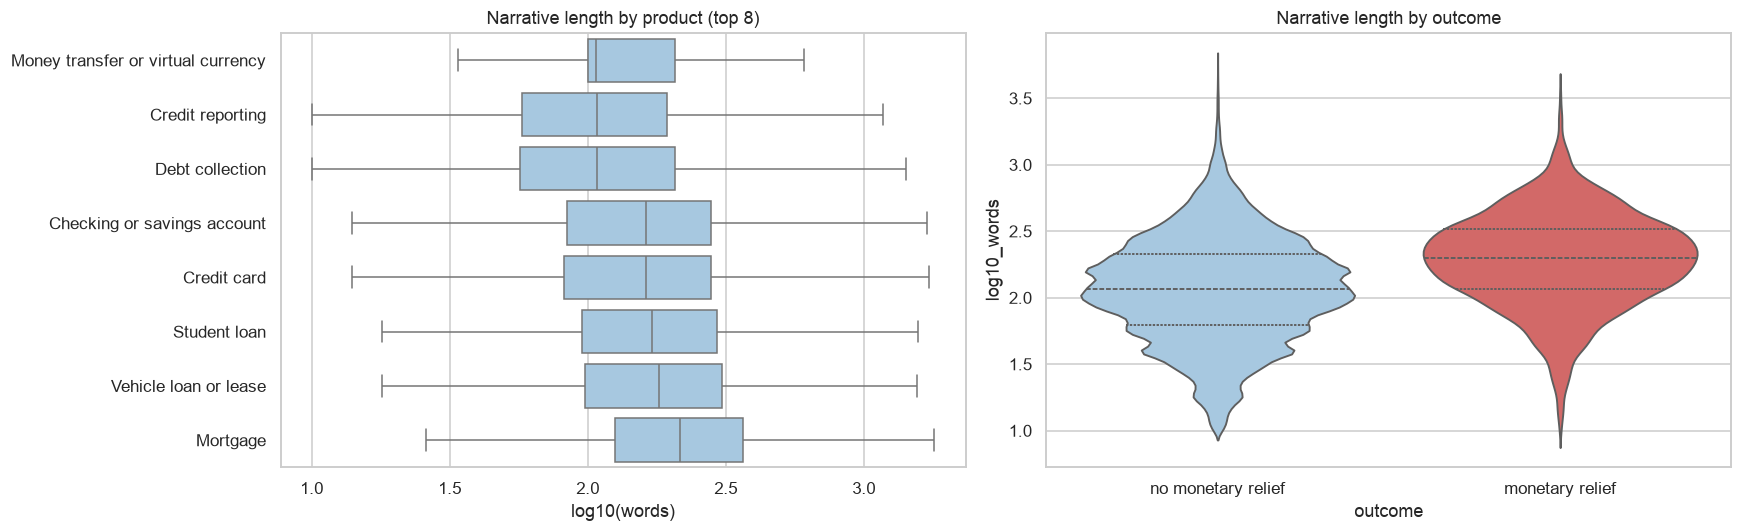

,n,relief_rate
mentions_dollar,,
False,587227,0.012
True,169039,0.076


,n,relief_rate
templated,,
False,549273,0.036
True,206993,0.000


In [26]:
top_products = df_text["product_clean"].value_counts().head(8).index
top_prod_rows = df_text[df_text["product_clean"].isin(top_products)]
plot_df = top_prod_rows.sample(min(len(top_prod_rows), 200_000), random_state=RANDOM_STATE)
plot_df = plot_df.assign(log10_words=np.log10(plot_df["word_count"].clip(lower=1)))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
order = plot_df.groupby("product_clean", observed=True)["log10_words"].median().sort_values().index
sns.boxplot(data=plot_df, y="product_clean", x="log10_words", order=order, showfliers=False, color="#9ecae9", ax=axes[0])
axes[0].set_title("Narrative length by product (top 8)")
axes[0].set_xlabel("log10(words)")
axes[0].set_ylabel("")

rel_plot = df_rel.sample(min(len(df_rel), 200_000), random_state=RANDOM_STATE)
rel_plot = rel_plot.assign(log10_words=np.log10(rel_plot["word_count"].clip(lower=1)),
                           outcome=rel_plot["relief"].map({0.0: "no monetary relief", 1.0: "monetary relief"}))
sns.violinplot(data=rel_plot, x="outcome", y="log10_words", inner="quartile", palette=["#9ecae9", "#E45756"], hue="outcome", legend=False, ax=axes[1])
axes[1].set_title("Narrative length by outcome")
savefig("13_text_length")

# Do consumers who mention a dollar amount get relief more often?
dollar = df_rel.assign(mentions_dollar=df_rel["n_dollar"] > 0).groupby("mentions_dollar")["relief"].agg(["size", "mean"])
display(dollar.rename(columns={"size": "n", "mean": "relief_rate"}))

# Template letters (text shared with another complaint, section 4.2) vs unique narratives
templ = df_rel.assign(templated=df_rel["narrative_repeat_count"] > 1).groupby("templated")["relief"].agg(["size", "mean"])
display(templ.rename(columns={"size": "n", "mean": "relief_rate"}))

In [27]:
STOP = list(ENGLISH_STOP_WORDS | {"xxxx", "xx", "xxxxxxxx"})
tx = df_text.sample(min(len(df_text), 100_000), random_state=RANDOM_STATE)
vec = TfidfVectorizer(stop_words=STOP, token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z]+\b", min_df=20, max_df=0.5,
                      max_features=20_000, ngram_range=(1, 2), sublinear_tf=True, dtype=np.float32)
X = vec.fit_transform(tx["narrative"].astype(str))
terms = np.array(vec.get_feature_names_out())
print("TF-IDF matrix:", X.shape)

overall_mean = np.asarray(X.mean(axis=0)).ravel()
prod_vals = tx["product_clean"].astype(str).to_numpy()
distinctive = {}
for prod in df_text["product_clean"].value_counts().head(8).index.astype(str):
    m = prod_vals == prod
    if m.sum() < 50:
        continue
    lift = np.asarray(X[m].mean(axis=0)).ravel() - overall_mean
    distinctive[prod[:38]] = terms[np.argsort(lift)[::-1][:10]]
display(pd.DataFrame(distinctive))

TF-IDF matrix: (100000, 20000)


,Credit reporting,Debt collection,Credit card,Checking or savings account,Mortgage,Money transfer or virtual currency,Student loan,Vehicle loan or lease
0,reporting,debt,card,bank,mortgage,app,loans,car
1,credit report,collection,credit card,funds,loan,cash app,loan,vehicle
2,accounts,company,bank,money,home,cash,student,loan
3,consumer,collect,charges,account,escrow,transfer,navient,payment
4,section,validation,called,checking,modification,money,student loan,auto
5,information,owe,charge,check,payment,platform,payments,payments
6,inaccurate,collector,capital,deposit,property,zelle,mohela,finance
7,inquiries,debt collection,payment,checking account,foreclosure,vulnerable,forbearance,repossession
8,items,debt collector,told,told,payments,funds,student loans,told
9,credit reporting,collection agency,chase,branch,insurance,paypal,repayment,dealership


In [28]:
# Terms most associated with relief (chi-square on TF-IDF), with the direction of the association
tr = df_rel.sample(min(len(df_rel), 100_000), random_state=RANDOM_STATE)
X_rel = vec.transform(tr["narrative"].astype(str))
y_rel = tr["relief"].to_numpy()
scores, pvals = chi2(X_rel, y_rel)
scores = np.nan_to_num(scores)
direction = (np.asarray(X_rel[y_rel == 1].mean(axis=0)).ravel() - np.asarray(X_rel[y_rel == 0].mean(axis=0)).ravel())

term_df = pd.DataFrame({"term": terms, "chi2": scores, "p": pvals, "tfidf_gap": direction})
top_chi = term_df.nlargest(300, "chi2")
display(pd.DataFrame({
    "more common in RELIEF complaints": top_chi.nlargest(15, "tfidf_gap")["term"].to_numpy(),
    "more common in NO-relief complaints": top_chi.nsmallest(15, "tfidf_gap")["term"].to_numpy(),
}))

,more common in RELIEF complaints,more common in NO-relief complaints
0,bank,reporting
1,card,credit report
2,fee,accounts
3,told,consumer
4,called,information
5,charges,inaccurate
6,money,section
7,bank america,debt
8,charge,credit reporting
9,america,agency


**What 6.7 shows.**
- **Routing:** each product has its own clear vocabulary (*escrow, foreclosure, modification* for mortgage; *cash app, zelle, paypal* for money transfer; *navient, mohela, forbearance* for student loans). Even a bag-of-words model should route well. The hard cases are the classes that share a vocabulary (credit reporting vs debt collection).
- **Relief:** the terms that separate relief complaints are about *money taken by a bank or card issuer* (*fee, charges, refund, bank america, credit card*). The no-relief terms are credit-report dispute language (*reporting, inaccurate, fcra, section*). Much of the text signal is therefore product signal, which is why the structured-only baseline in the proposal is the right comparison.
- Mentioning a dollar amount raises the relief rate from 1.2% to 7.6%, and **templated narratives almost never get monetary relief** (0.01% vs 3.6%).

### 6.8 Time: volume, mix and drift
The proposal evaluates on a **later time period**, so anything that shifts over time (product mix, relief rate) directly affects how the split must be designed. This section also suggests where to cut.

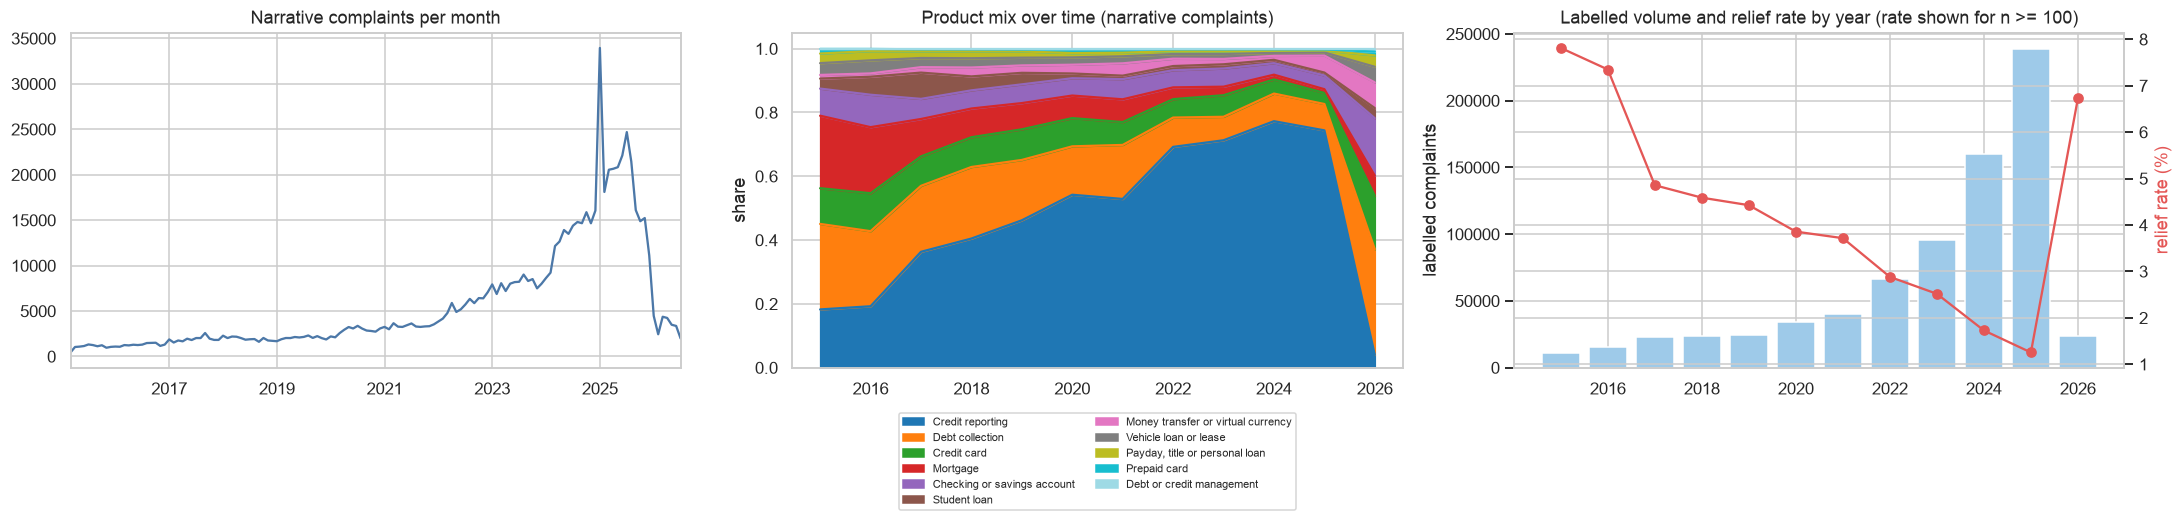

2026: narrative opt-in 2.5% vs 22.3% in 2025 -> reported as a separate out-of-distribution slice, not part of the train/test split.
Credit reporting share of narratives, last 3 years: {2024: 0.773, 2025: 0.744, 2026: 0.04}
Suggested hold-out window: complaints received in 2025 or later (32.6% of labelled rows in 2015-2025); train on earlier years.


In [29]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

monthly = df_text.groupby(df_text["date_received"].dt.to_period("M")).size()
monthly.index = monthly.index.to_timestamp()
monthly.plot(ax=axes[0], color="#4C78A8")
axes[0].set_title("Narrative complaints per month")
axes[0].set_xlabel("")

mix = pd.crosstab(df_text["year"], df_text["product_clean"], normalize="index")
mix = mix[mix.mean().sort_values(ascending=False).index]
mix.plot(kind="area", stacked=True, ax=axes[1], legend=False, colormap="tab20")
axes[1].set_title("Product mix over time (narrative complaints)")
axes[1].set_ylabel("share")
axes[1].set_xlabel("")
axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, fontsize=7)

yr_rel = df_rel.groupby("year")["relief"].agg(["size", "mean"])
axes[2].bar(yr_rel.index, yr_rel["size"], color="#9ecae9")
axes[2].set_ylabel("labelled complaints")
ax2 = axes[2].twinx()
solid = yr_rel[yr_rel["size"] >= 100]                       # years with fewer than 100 labelled rows are too noisy to plot
ax2.plot(solid.index, solid["mean"] * 100, color="#E45756", marker="o")
ax2.set_ylabel("relief rate (%)", color="#E45756")
axes[2].set_title("Labelled volume and relief rate by year (rate shown for n >= 100)")
savefig("14_time_drift")

# The final year is set aside if its narrative opt-in rate collapsed (under half of the year before):
# its narratives are no longer a like-for-like sample of complaints (see the product-mix panel).
optin_by_year = df.groupby("year")["has_narrative"].mean()
final = int(yr_rel.index.max())
collapsed = [final] if optin_by_year.loc[final] < 0.5 * optin_by_year.loc[final - 1] else []
if collapsed:
    print(f"{final}: narrative opt-in {optin_by_year.loc[final]:.1%} vs {optin_by_year.loc[final - 1]:.1%} in {final - 1} "
          f"-> reported as a separate out-of-distribution slice, not part of the train/test split.")
cr_share = mix.get("Credit reporting", pd.Series(dtype=float))
print("Credit reporting share of narratives, last 3 years:", cr_share.tail(3).round(3).to_dict())
yr_split = yr_rel.drop(index=collapsed)

# Suggested time-based split: the latest years that together hold about 15% of the labelled rows
tail_share = 1 - yr_split["size"].cumsum().shift(fill_value=0) / yr_split["size"].sum()
split_year = int(tail_share[tail_share >= 0.15].index.max())
test_share = yr_split.loc[yr_split.index >= split_year, "size"].sum() / yr_split["size"].sum()
print(f"Suggested hold-out window: complaints received in {split_year} or later "
      f"({test_share:.1%} of labelled rows in {int(yr_split.index.min())}-{int(yr_split.index.max())}); train on earlier years.")

**What 6.8 shows.**
- Volume grows sharply from 2022 (credit-reporting complaints in particular), and narratives peak in early 2025.
- The **relief rate falls steadily from 7.8% (2015) to 1.3% (2025)** while credit reporting grows from about 20% to about 75% of narratives. Much of the decline is product mix, not companies becoming less generous.
- **2026 is a different population.** Narrative opt-in collapses from January 2026, and the narratives that remain are mostly *not* credit reporting, so the 2026 relief rate (6.7%) cannot be compared with earlier years.
- Consequence for modelling: train on 2015–2024, hold out 2025 (the most recent like-for-like year, about a third of labelled rows; the split code above derives this), report 2026 separately, and stratify or re-weight by product when comparing periods.

### 6.9 Leakage audit and feature shortlist
Columns that only exist *after* the company has responded would let a model "predict" relief by reading its consequences. The audit measures how strongly each post-outcome column is tied to the target. A strong tie confirms it must be excluded. The shortlist then ranks the remaining features by association with each task.

In [30]:
leak_rows = []
LEAK_CATS = present(["company_public_response", "timely_response", "consumer_disputed"])
for c in LEAK_CATS:
    ct = pd.crosstab(df_rel[c], df_rel["relief"], normalize="index")[1.0].sort_values(ascending=False) * 100
    leak_rows.append({"column": c, "cramers_v_relief": cat_assoc.loc[c, "cramers_v_relief"],
                      "highest_relief_rate_level": f"{str(ct.index[0])[:40]} ({ct.iloc[0]:.1f}%)",
                      "lowest_relief_rate_level": f"{str(ct.index[-1])[:40]} ({ct.iloc[-1]:.1f}%)"})
leak_df = pd.DataFrame(leak_rows).set_index("column")
display(leak_df)

x = df_rel[["days_to_company", "relief"]].dropna()
r_days, _ = stats.pearsonr(x["days_to_company"], x["relief"])
print(f"days_to_company vs relief: Pearson r = {r_days:.3f}  (also a post-submission processing field)")
display(pd.crosstab(df_rel["company_public_response"], df_rel["relief"], normalize="index").mul(100).round(1).head(12))

,cramers_v_relief,highest_relief_rate_level,lowest_relief_rate_level
column,,,
company_public_response,0.041,Company believes complaint is the result (11.6%),Company can't verify or dispute the fact (0.0%)
timely_response,0.006,No (3.7%),Yes (2.6%)


days_to_company vs relief: Pearson r = 0.014  (also a post-submission processing field)


relief,0.000,1.000
company_public_response,,
Company believes complaint caused principally by actions of third party outside the control or direction of the company,97.500,2.500
Company believes complaint is the result of an isolated error,88.400,11.600
Company believes complaint relates to a discontinued policy or procedure,100.000,0.000
Company believes complaint represents an opportunity for improvement to better serve consumers,90.500,9.500
Company believes it acted appropriately as authorized by contract or law,97.300,2.700
Company believes the complaint is the result of a misunderstanding,97.500,2.500
Company believes the complaint provided an opportunity to answer consumer's questions,97.000,3.000
Company can't verify or dispute the facts in the complaint,100.000,0.000
Company chooses not to provide a public response,88.900,11.100


,kind,assoc_relief,assoc_product,recommendation,strength
feature,,,,,
company_response,categorical,1.000,0.264,outcome: the source of the relief target (not a feature),strong
issue,categorical,0.363,0.716,routing target (task 1); known input for relief (task 2),strong
product_clean,categorical,0.339,NaN,routing target (task 1); known input for relief (task 2),strong
company,categorical,0.334,0.468,candidate input,strong
sub_product,categorical,0.329,0.873,level-2 routing label; known input for relief,strong
sub_issue,categorical,0.321,0.512,level-2 routing label; known input for relief,strong
n_dollar,numeric,0.171,NaN,candidate input,moderate
word_count,numeric,0.091,NaN,candidate input,weak
char_len,numeric,0.085,NaN,candidate input,weak


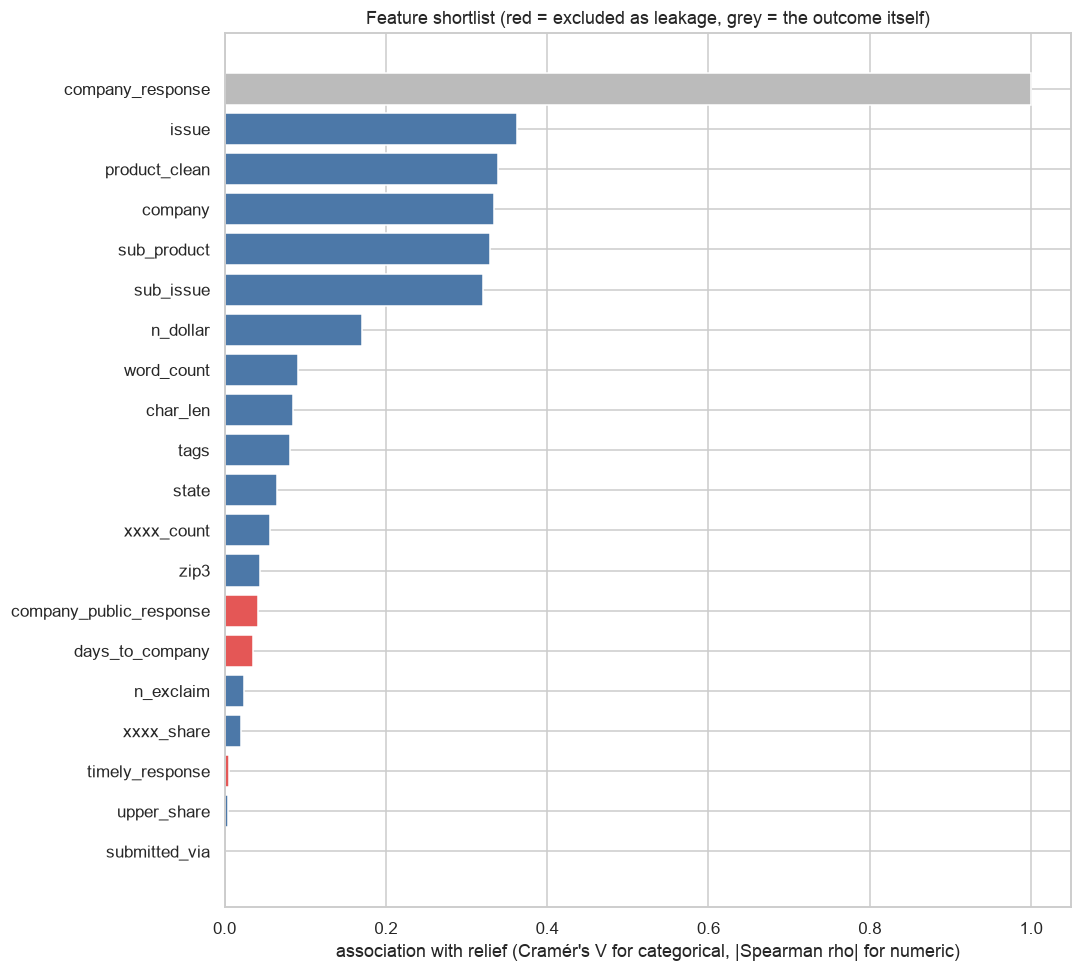

In [31]:
ROLE = {
    "company_response": "outcome: the source of the relief target (not a feature)",
    "product_clean": "routing target (task 1); known input for relief (task 2)",
    "issue": "routing target (task 1); known input for relief (task 2)",
    "sub_product": "level-2 routing label; known input for relief",
    "sub_issue": "level-2 routing label; known input for relief",
}
rows = []
for c, r in cat_assoc.iterrows():
    if c in ROLE:
        rec = ROLE[c]
    elif c in POST_OUTCOME:
        rec = "EXCLUDE: post-outcome / leakage"
    elif pd.isna(r["cramers_v_relief"]):
        rec = "constant in the analysed subset (carries no information)"
    else:
        rec = "candidate input"
    rows.append({"feature": c, "kind": "categorical", "assoc_relief": r["cramers_v_relief"],
                 "assoc_product": r.get("cramers_v_product", np.nan), "recommendation": rec})
for c, r in num_vs_relief.iterrows():
    rows.append({"feature": c, "kind": "numeric", "assoc_relief": abs(r["spearman_rho"]), "assoc_product": np.nan,
                 "recommendation": "EXCLUDE: post-submission processing field" if c in POST_OUTCOME else "candidate input"})

shortlist = pd.DataFrame(rows).set_index("feature").sort_values("assoc_relief", ascending=False)
shortlist["strength"] = pd.cut(shortlist["assoc_relief"], [-0.01, 0.05, 0.10, 0.30, 1.0],
                               labels=["negligible", "weak", "moderate", "strong"])
display(shortlist)

fig, ax = plt.subplots(figsize=(10, 0.35 * len(shortlist) + 2))
colors = ["#E45756" if str(r).startswith("EXCLUDE") else "#BBBBBB" if str(r).startswith("outcome") else "#4C78A8"
          for r in shortlist["recommendation"]]
ax.barh(shortlist.index[::-1], shortlist["assoc_relief"][::-1].fillna(0), color=colors[::-1])
ax.set_xlabel("association with relief (Cramér's V for categorical, |Spearman rho| for numeric)")
ax.set_title("Feature shortlist (red = excluded as leakage, grey = the outcome itself)")
savefig("15_feature_shortlist")

**How the shortlist is used:** columns marked `EXCLUDE` stay out of the relief model. `product_clean`, `issue` and their sub-levels are labels for task 1 and legitimate inputs for task 2. Among the remaining candidates, those rated at least *weak* are the structured features to carry forward as the baseline. The text-versus-structured comparison in the proposal then measures how much the narrative adds on top of them.

## 7. Save outputs and summarise
Outputs: the full cleaned dataset (local only, too large for GitHub) and a 5,000-row random sample of narrative complaints that is small enough to commit so the repo contains real data alongside the code.

Saved full cleaned data: data/processed/complaints_clean.parquet (406.7 MB)
Saved GitHub-sized sample: data/sample/complaints_clean_sample_5k.csv (7.4 MB)


,step,rows,columns,note,rows_removed_vs_previous
0,1. raw exports loaded (20% sample),3505876,16,"17,533,918 rows in the files",0
1,"2. types fixed, blanks -> NaN",3505876,16,,0
2,4.1 dropped rows missing id/date/product,3505876,16,0 rows,0
3,4.2a dropped duplicate complaint_id,3505876,17,0 rows,0
4,4.2b dropped duplicate content,3502150,17,"3,726 rows",3726
5,4.3 dropped impossible date_received,3502150,19,0 rows,0
6,4.4 text_usable flag (no rows dropped),3502150,27,"758,548 usable narratives",0
7,"4.6 targets built, categories typed",3502150,30,,0


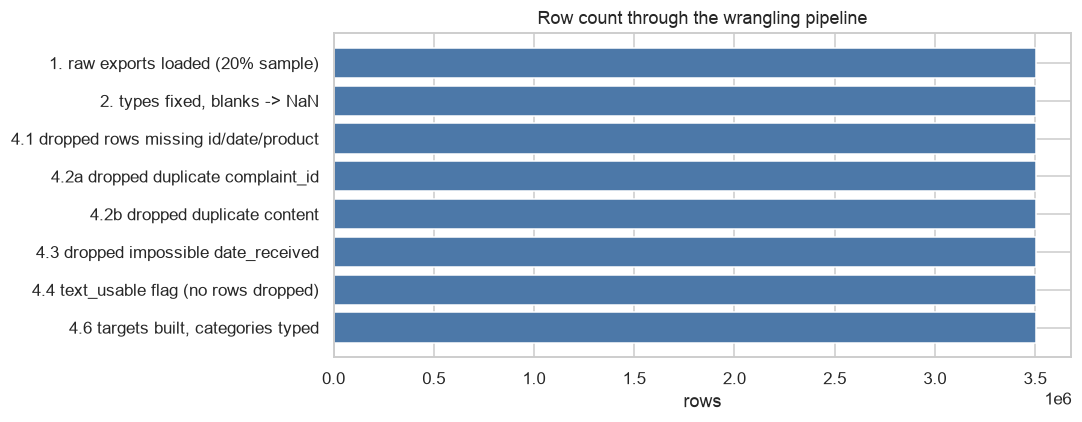

In [32]:
OUT_COLS = [c for c in df.columns if c not in ("zip_code",)]
try:
    full_path = PROCESSED_DIR / "complaints_clean.parquet"
    df[OUT_COLS].to_parquet(full_path, index=False)
except Exception as e:  # pyarrow/fastparquet not installed
    print("Parquet unavailable (", type(e).__name__, ") -> writing compressed CSV instead")
    full_path = PROCESSED_DIR / "complaints_clean.csv.gz"
    df[OUT_COLS].to_csv(full_path, index=False)
print("Saved full cleaned data:", full_path.relative_to(ROOT), f"({full_path.stat().st_size / 1e6:,.1f} MB)")

sample_path = SAMPLE_DIR / "complaints_clean_sample_5k.csv"
sample = df_text.sample(min(5000, len(df_text)), random_state=RANDOM_STATE)
sample[OUT_COLS].to_csv(sample_path, index=False)
print("Saved GitHub-sized sample:", sample_path.relative_to(ROOT), f"({sample_path.stat().st_size / 1e6:,.1f} MB)")

# Wrangling audit trail
log_df = pd.DataFrame(wrangling_log)
log_df["rows_removed_vs_previous"] = (-log_df["rows"].diff()).fillna(0).astype(int)
display(log_df)

fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(log_df["step"][::-1], log_df["rows"][::-1], color="#4C78A8")
ax.set_xlabel("rows")
ax.set_title("Row count through the wrangling pipeline")
savefig("16_wrangling_log")

In [33]:
# Findings are generated from the computed results above, so every number and every qualitative
# statement follows from this run's data rather than being typed in.
def effect_word(x):
    return "negligible" if x < 0.1 else "small" if x < 0.3 else "medium" if x < 0.5 else "large"


n_raw = wrangling_log[0]["rows"]
last_year = int(df["year"].max())
optin_all = df["has_narrative"].mean()
optin_last = df.loc[df["year"] == last_year, "has_narrative"].mean()
top_prod = df_text["product_clean"].value_counts(normalize=True)
imb = balance["n"].max() / balance["n"].min()
prod_rates = rate_table(df_rel, "product_clean", 500)

lines = ["### Key findings"]
_log = pd.DataFrame(wrangling_log).assign(removed=lambda t: (-t["rows"].diff()).fillna(0).astype(int))
removed_steps = _log[_log["removed"] > 0].to_dict("records")
lines.append(f"- **Data volume.** The 21 archive exports hold {N_RAW_TOTAL:,} complaints (Dec 2011 to Aug 2026) with no duplicate IDs. "
             + (f"A random {SAMPLE_FRAC:.0%} sample ({n_raw:,} rows) was analysed; " if SAMPLE_FRAC else "")
             + f"{len(df):,} rows remain after cleaning ({n_raw - len(df):,} removed; by step: "
             + ", ".join(f"{r['step'].split(' ', 1)[1]} {r['removed']:,}" for r in removed_steps) + ").")
yr_optin = df.groupby("year")["has_narrative"].mean()
lines.append(f"- **Narrative subset.** {optin_all:.1%} of all complaints have a narrative. Narratives start in {int(df.loc[df['has_narrative'], 'year'].min())}, "
             f"and the opt-in rate falls from a peak of {yr_optin.max():.0%} ({yr_optin.idxmax()}) to {yr_optin.loc[last_year - 1]:.0%} in {last_year - 1} "
             f"and {optin_last:.1%} in {last_year} (the drop starts in January {last_year}; publication ended in August {last_year}). "
             f"{len(df_text):,} narratives are long enough to model, and {len(df_rel):,} of those also have a defined relief label. "
             f"Every narrative was submitted via the web form, so `submitted_via` carries no information for the text tasks.")
lines.append(f"- **Repeated text.** {n_repeat_rows:,} complaints share their narrative text with another complaint "
             f"(template letters, mostly credit-reporting disputes, filed by different consumers). Their monetary-relief rate is "
             f"{templ.loc[True, 'mean']:.2%} vs {templ.loc[False, 'mean']:.1%} for unique narratives, so being templated is a strong negative signal; "
             f"they are flagged with `narrative_hash` so a split can keep them together.")
lines.append(f"- **Product mix.** {df['product_clean'].nunique()} harmonised products; the largest, *{top_prod.index[0]}*, is "
             f"{top_prod.iloc[0]:.1%} of usable narratives. Legacy labels flagged: {legacy_products or 'none'}.")

rel_all = df.groupby("has_narrative")["relief"].mean()
bal = (f"- **Target balance.** Monetary relief is {OVERALL_RELIEF:.1%} of labelled narrative complaints ({imb:.1f}:1 majority:minority), "
       f"against {rel_all.loc[False]:.1%} for complaints without a narrative, so consumers who write a narrative get money back "
       f"{rel_all.loc[True] / rel_all.loc[False]:.1f}x as often.")
if imb >= 3:
    bal += " Accuracy would be a misleading metric here; average precision and top-10% precision (as planned in the proposal) suit it better."
lines.append(bal)

if len(prod_rates) >= 2:
    lines.append(f"- **Where relief varies.** Highest product rate: *{prod_rates.index[-1]}* ({prod_rates['rate'].iloc[-1]:.1%}); "
                 f"lowest: *{prod_rates.index[0]}* ({prod_rates['rate'].iloc[0]:.1%}), among products with at least 500 labelled complaints.")

lines.append(f"- **Leakage.** " + ", ".join(f"`{c}`" for c in LEAK_CATS + ["days_to_company"]) + " only exist after the company "
             f"responds, so they are excluded by design. Their association with relief reaches Cramér's V = {leak_df['cramers_v_relief'].max():.2f}, "
             f"and |Pearson r| = {abs(r_days):.2f} for `days_to_company`. They are weak, but they are excluded anyway because they are not available at filing time.")

usable_rows = shortlist[~shortlist["recommendation"].str.startswith(("EXCLUDE", "outcome", "constant"))]
cand = usable_rows[usable_rows["strength"].isin(["weak", "moderate", "strong"])]
if len(cand):
    lines.append("- **Structured inputs with at least a weak association with relief:** "
                 + ", ".join(f"`{i}` ({v:.2f}, {usable_rows.loc[i, 'strength']})" for i, v in cand["assoc_relief"].head(6).items()) + ".")
else:
    lines.append("- **Structured inputs:** none of the non-leaking structured features reaches even a weak association with relief, "
                 "which makes the narrative the main place to look for signal.")

top_num = num_vs_relief["rank_biserial"].abs().sort_values(ascending=False)
if len(top_num):
    lines.append(f"- **Text-shape features vs relief.** The largest effect is `{top_num.index[0]}` (|rank-biserial| = {top_num.iloc[0]:.2f}, "
                 f"{effect_word(top_num.iloc[0])} by the usual rule of thumb).")
lines.append("- **Terms most associated with relief:** " + ", ".join(f"`{t}`" for t in top_chi.nlargest(6, "tfidf_gap")["term"]) + ".")

ok_years = yr_rel[yr_rel["size"] >= 100]
vol = df_text["year"].value_counts()
yrs = sorted(y for y in vol[vol >= 500].index if y not in collapsed)
drift = []
if len(ok_years) >= 2:
    drift.append(f"Relief rate ranges from {ok_years['mean'].min():.1%} ({ok_years['mean'].idxmin()}) to {ok_years['mean'].max():.1%} ({ok_years['mean'].idxmax()})")
if len(yrs) >= 2:
    shift = 0.5 * (mix.loc[yrs[-1]] - mix.loc[yrs[0]]).abs().sum()
    drift.append(f"{shift:.0%} of the product mix would have to move to turn {yrs[0]}'s mix into {yrs[-1]}'s")
lines.append("- **Drift and split.** " + ("; ".join(drift) + ". " if drift else "")
             + f"A time-based split with hold-out from {split_year} holds {test_share:.0%} of labelled rows"
             + (f" ({', '.join(map(str, collapsed))} kept aside)." if collapsed else "."))
if last_year in yr_rel.index:
    lines.append(f"- **{last_year} is atypical.** Only {int(yr_rel.loc[last_year, 'size']):,} labelled narratives "
                 f"with a relief rate of {yr_rel.loc[last_year, 'mean']:.1%} against {yr_rel.loc[last_year - 1, 'mean']:.1%} in {last_year - 1}. "
                 f"This is a composition effect: credit reporting falls from {cr_share.loc[last_year - 1]:.0%} of narratives in {last_year - 1} "
                 f"to {cr_share.loc[last_year]:.0%} in {last_year}. The year is reported as its own slice, not pooled into the test set.")
display(Markdown("\n".join(lines)))

### Key findings
- **Data volume.** The 21 archive exports hold 17,533,918 complaints (Dec 2011 to Aug 2026) with no duplicate IDs. A random 20% sample (3,505,876 rows) was analysed; 3,502,150 rows remain after cleaning (3,726 removed; by step: dropped duplicate content 3,726).
- **Narrative subset.** 21.9% of all complaints have a narrative. Narratives start in 2015, and the opt-in rate falls from a peak of 48% (2017) to 22% in 2025 and 2.5% in 2026 (the drop starts in January 2026; publication ended in August 2026). 758,548 narratives are long enough to model, and 756,266 of those also have a defined relief label. Every narrative was submitted via the web form, so `submitted_via` carries no information for the text tasks.
- **Repeated text.** 209,868 complaints share their narrative text with another complaint (template letters, mostly credit-reporting disputes, filed by different consumers). Their monetary-relief rate is 0.01% vs 3.6% for unique narratives, so being templated is a strong negative signal; they are flagged with `narrative_hash` so a split can keep them together.
- **Product mix.** 11 harmonised products; the largest, *Credit reporting*, is 64.8% of usable narratives. Legacy labels flagged: none.
- **Target balance.** Monetary relief is 2.6% of labelled narrative complaints (37.3:1 majority:minority), against 0.9% for complaints without a narrative, so consumers who write a narrative get money back 2.9x as often. Accuracy would be a misleading metric here; average precision and top-10% precision (as planned in the proposal) suit it better.
- **Where relief varies.** Highest product rate: *Prepaid card* (19.8%); lowest: *Credit reporting* (0.1%), among products with at least 500 labelled complaints.
- **Leakage.** `company_public_response`, `timely_response`, `days_to_company` only exist after the company responds, so they are excluded by design. Their association with relief reaches Cramér's V = 0.04, and |Pearson r| = 0.01 for `days_to_company`. They are weak, but they are excluded anyway because they are not available at filing time.
- **Structured inputs with at least a weak association with relief:** `issue` (0.36, strong), `product_clean` (0.34, strong), `company` (0.33, strong), `sub_product` (0.33, strong), `sub_issue` (0.32, strong), `n_dollar` (0.17, moderate).
- **Text-shape features vs relief.** The largest effect is `n_dollar` (|rank-biserial| = 0.45, medium by the usual rule of thumb).
- **Terms most associated with relief:** `bank`, `card`, `fee`, `told`, `called`, `charges`.
- **Drift and split.** Relief rate ranges from 1.3% (2025) to 7.8% (2015); 60% of the product mix would have to move to turn 2015's mix into 2025's. A time-based split with hold-out from 2025 holds 33% of labelled rows (2026 kept aside).
- **2026 is atypical.** Only 23,848 labelled narratives with a relief rate of 6.7% against 1.3% in 2025. This is a composition effect: credit reporting falls from 74% of narratives in 2025 to 4% in 2026. The year is reported as its own slice, not pooled into the test set.

### Next steps (Pre-processing and training data development)
1. Build the time-based split from section 6.8: train on 2015–2024, hold out 2025, and report 2026 as a separate out-of-distribution slice. Group by `narrative_hash` so identical templated text never straddles train and test.
2. Routing labels: use the 11 harmonised products from section 4.5. All of them are active in the evaluation window, so no legacy classes need to be dropped. `issue` (172 raw labels) needs the same old-to-new harmonisation before it can be a routing target.
3. Fit the baselines named in the proposal (majority class, structured fields only) using the *candidate* features from section 6.9 and none of the excluded columns. Add `narrative_repeat_count > 1` (templated text) and `n_dollar` as engineered inputs.
4. Vectorise narratives (TF-IDF first, sentence embeddings second) on the training period only. Because credit reporting dominates (65% of narratives), use class weights or stratified sampling for routing.
5. Evaluate with macro-F1 for routing and average precision / top-10% precision for relief (2.6% positives), reported overall and per product.